# Parte I

a instalação de sistemas PV deve ser distribuída por pelo menos 20% das barras do sistema.

inicialmente, o total de geração PV deve ser dimensionado para atender à demanda total, considerando as cargas com o valor de pico.

fazer as simulações para os seguintes cenários:

1. sistema sem geração PV e cargas com valor de pico;
2. sistema sem geração PV e cargas com 20% do valor de pico;
3. sistema com geração PV e cargas com 20% do valor de pico;
4. sistema com geração PV e cargas com valor de pico.

Em cada cenário, as métricas sobretensão e sobrecarga nas linhas e transformadores devem ser avaliadas bem como o nível de fluxo reverso e perdas no sistema.

Para o cenário 4, caso não haja violação de limites operativos de tensão e carregamento nos elementos, aumente gradativamente a geração PV e verifique em quais níveis de geração PV as violações ocorrem.


Compare e discuta os resultados obtidos.
# Parte II

Agregar ao circuito com elevada capacidade de geração instalada, um sistema de armazenamento de energia (armazenamento central e armazenamento distribuído), de forma que a energia excedente seja armazenada e os impactos da geração renovável sejam mitigados. Compare os resultados obtidos com as duas abordagens.

# Parte III

Crie uma Microrrede em parte do circuito e mostre a operação ilhada da rede, avaliando seu tempo de sobrevivência. Simule o ilhamento em diferentes cenários.

Aplique uma metodologia de corte de carga para aumento de tempo de sobrevivência.

########################################################################################################################################################

##Simulação 1: ###PV false, loadmult=1,
##Simulação 2: ###PV false, loadmult=0.2,
##Simulação 3: ###PV true,  loadmult=1,
##Simulação 4: ###PV true,  loadmult=0.2,
##Simulação 5: ###PV true,  loadmult=1,   pmpp=400 ,kva=500
##Simulação 6: ###PV true,  loadmult=1,   pmpp=400 ,kva=500, Storage Distribuido
##Simulação 7: ###PV true,  loadmult=1,   pmpp=400 ,kva=500, Storage Central
##Simulação 8: ###PV true,  loadmult=1,   pmpp=400 ,kva=500, Storage Distribuido, Ilhamento L27, situacao 1
##Simulação 9: ###PV true,  loadmult=1,   pmpp=400 ,kva=500, Storage Distribuido, Ilhamento L27, situacao 2

In [123]:
%pip install -qqq --upgrade pip
%pip install -qqq numpy
%pip install -qqq pypiwin32
%pip install -qqq pandas
%pip install -qqq matplotlib
%pip install -qqq dss-python


Note: you may need to restart the kernel to use updated packages.

Note: you may need to restart the kernel to use updated packages.

Note: you may need to restart the kernel to use updated packages.

Note: you may need to restart the kernel to use updated packages.

Note: you may need to restart the kernel to use updated packages.

Note: you may need to restart the kernel to use updated packages.


In [124]:
import numpy as np    #np, mpl and pd serve as a nicknames
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import os
import dss #OpenDss Module

os.chdir('C:\\Users\\brun\\Desktop\\aff\\bla\\') 
#os.chdir('C:\\Users\\aptis\\downloads\\aff\\bla\\')   # force going to the working folder (ADJUST FOR YOUR OWN PATH!)
mydir=os.getcwd()                          # mydir stores the working path

dss_engine = dss.DSS
DSSText = dss_engine.Text                                                      
DSSCircuit = dss_engine.ActiveCircuit                                            
DSSSolution = dss_engine.ActiveCircuit.Solution                                      
ControlQueue = dss_engine.ActiveCircuit.CtrlQueue  

def compile():
    DSSText.Command = f'Compile "{mydir}/ieee37.dss"'

In [125]:
def criar_curvas():
    DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'
    DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'
    DSSText.Command = 'New loadshape.Irrad npts=24 interval=1 mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0]'
    DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
    #print('PV curves created')


def pvsystem(nome, phases, bus1, pmpp, kva, kv, conn):
    for n, b in zip(nome, bus1):
        cmd = (f"New PVSystem.{n} phases={phases} bus1={b} kv={kv} conn={conn} "
               f"irrad=1.0 pmpp={pmpp} kva={kva} temperature=25 pf=1 "
               f"%cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT "
               f"Daily=Irrad Tdaily=Temp")
        DSSText.Command = cmd
        #print(f"{n} created")

In [126]:
def criar_curvas_storage():
    DSSText.Command = 'New XYcurve.Eff npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'
    DSSText.Command = ('New LoadShape.dispatch_shape npts=24 interval=1 '
                       'mult=[0 0 0 0 0 0 0 0 0 0 -0.3 -0.4 -0.45 -0.45 -0.45 -0.4 -0.15 0.2 0.4 0.6 0.6 0.4 0.2 0]')
    #print('Storage curves created')


def storage(nome, phases, bus1, kv, conn, kWrated, kWhrated, stored, reserve):
    for n, b in zip(nome, bus1):
        DSSText.Command = (f"New Storage.{n} phases={phases} bus1={b} kv={kv} conn={conn} "
                           f"kWrated={kWrated} kWhrated={kWhrated} %stored={stored} %reserve={reserve} "
                           f"effcurve=Eff dispmode=follow daily=dispatch_shape pf=1")
        #print(f"{n} created")

In [127]:
def ilhamento(linhailha, cargas_ilha, n_corte, nomes_sto, nomes_pv):
    # abre a linha (ex: L27 no terminal 1)
    DSSText.Command = f"Open Line.{linhailha} Term=1"

    # corte de carga, na ordem da lista
    for nome, kw in cargas_ilha[:n_corte]:
        DSSText.Command = f"Edit Load.{nome} enabled=no"

    # controle grid forming
    der = ", ".join([f"Storage.{n}" for n in nomes_sto] +
                    [f"PVSystem.{n}" for n in nomes_pv])
    DSSText.Command = f"New InvControl.StoCtrl DERList=[{der}] mode=GFM"
    for n in nomes_sto:
        DSSText.Command = f"Edit Storage.{n} State=Discharging ControlMode=GFM"

In [128]:
def prepagar_cargas(DSSCircuit, Loadnames):
        ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

        resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45, 0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

        ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00, 0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

        DSSCircuit.LoadShapes.New('resd_loadshape')
        DSSCircuit.LoadShapes.Npts = 24
        DSSCircuit.LoadShapes.HrInterval = 1
        DSSCircuit.LoadShapes.Pmult = resd_profile
        DSSCircuit.LoadShapes.New('ind_loadshape')
        DSSCircuit.LoadShapes.Npts = 24
        DSSCircuit.LoadShapes.HrInterval = 1
        DSSCircuit.LoadShapes.Pmult = ind_profile
        
        for load in Loadnames:
            DSSCircuit.SetActiveElement('load.%s' % load)
            if load.lower() in ind_loads:
                DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
            else:
                DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

In [129]:
def get_element_names():
    Elenames = DSSCircuit.AllElementNames
    Loadnames = DSSCircuit.Loads.AllNames
    Busnames = DSSCircuit.AllBusNames
    Trafonames = DSSCircuit.Transformers.AllNames
    Linenames = DSSCircuit.Lines.AllNames
    Pvnames = DSSCircuit.PVSystems.AllNames
    Storagenames = DSSCircuit.Storages.AllNames

    # print('Elements:', Elenames)
    # print('Loads:', Loadnames)
    # print('Buses:', Busnames)
    # print('Transformers:', Trafonames)
    # print('Lines:', Linenames)
    # print('PV Systems:', Pvnames)
    # print('Storages:', Storagenames)
    
    # print('N Elements:', len(Elenames))
    # print('N Loads:', len(Loadnames))
    # print('N Buses:', len(Busnames))
    # print('N Transformers:', len(Trafonames))
    # print('N Lines:', len(Linenames))
    # print('N PV Systems:', len(Pvnames))
    # print('N Storages:', len(Storagenames))
    return Elenames, Loadnames, Busnames, Trafonames, Linenames, Pvnames, Storagenames

In [130]:
def powerflow(cfg, DSSCircuit, DSSSolution, DSSText):
    Loadnames = cfg["loadnames"]
    Linenames = cfg["linenames"]
    T = cfg["simulation_time"]
    pumin = cfg["pumin"]
    pumax = cfg["pumax"]
    # ind_loads = cfg["ind_loads"]
    # # preparar cargas
    # DSSCircuit.LoadShapes.New('resd_loadshape')
    # DSSCircuit.LoadShapes.Npts = 24
    # DSSCircuit.LoadShapes.HrInterval = 1
    # DSSCircuit.LoadShapes.Pmult = cfg["resd_profile"]

    # DSSCircuit.LoadShapes.New('ind_loadshape')
    # DSSCircuit.LoadShapes.Npts = 24
    # DSSCircuit.LoadShapes.HrInterval = 1
    # DSSCircuit.LoadShapes.Pmult = cfg["ind_profile"]
    # print('Loadshapes created')

    # for load in Loadnames:
    #     DSSCircuit.SetActiveElement('load.%s' % load)
    #     if load.lower() in ind_loads:
    #         DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    #     else:
    #         DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'
    #set min and max pu
    
    DSSText.Command = f'set normvminpu={pumin}'
    DSSText.Command = f'set normvmaxpu={pumax}'
    #print(f'Voltage limits set to {pumin} p.u. and {pumax} p.u.')

    DSSText.Command = f'set loadmult = {cfg["loadmult"]}'
    #print(f'Load multiplier set to {cfg["loadmult"]}')

    #run power flow 
    DSSText.Command = 'reset'
    DSSText.Command = 'set controlmode=static'
    DSSText.Command = 'set mode=daily'
    DSSText.Command = 'set stepsize=1h'
    DSSText.Command = 'set number=1'

    Pvnames = DSSCircuit.PVSystems.AllNames
    Storagenames = DSSCircuit.Storages.AllNames
    onlytrafo = [n for n in DSSCircuit.Transformers.AllNames if 'reg' not in n.lower()]

    Total_Act_Power = np.zeros(T)
    Total_React_Power = np.zeros(T)
    Total_Act_Losses = np.zeros(T)
    Total_React_Losses = np.zeros(T)
    busVpuA = [None] * T
    busVpuB = [None] * T
    busVpuC = [None] * T

    Trafo_Max_Amp = np.zeros((len(onlytrafo), T))
    Load_kW = np.zeros((len(Loadnames), T))
    Load_kvar = np.zeros((len(Loadnames), T))
    Line_Max_Amp = np.zeros((len(Linenames), T))
    PV_kW = np.zeros((len(Pvnames), T))
    Storage_kW = np.zeros((len(Storagenames), T))

    def corrente_maxima(elem):
        ncond = elem.NumConductors
        return max(elem.CurrentsMagAng[0:2*ncond:2])


    for h in range(T):
        DSSSolution.Solve()

        Total_Act_Power[h] = DSSCircuit.TotalPower[0]
        Total_React_Power[h] = DSSCircuit.TotalPower[1]
        Total_Act_Losses[h] = DSSCircuit.Losses[0] / 1000
        Total_React_Losses[h] = DSSCircuit.Losses[1] / 1000

        busVpuA[h] = DSSCircuit.AllNodeVmagPUByPhase(1)
        busVpuB[h] = DSSCircuit.AllNodeVmagPUByPhase(2)
        busVpuC[h] = DSSCircuit.AllNodeVmagPUByPhase(3)

        for i, t in enumerate(onlytrafo):
            DSSCircuit.SetActiveElement('Transformer.%s' % t)
            Trafo_Max_Amp[i, h] = corrente_maxima(DSSCircuit.ActiveElement)

        for i, l in enumerate(Loadnames):
            DSSCircuit.SetActiveElement('Load.%s' % l)
            Load_kW[i, h] = DSSCircuit.ActiveElement.TotalPowers[0]
            Load_kvar[i, h] = DSSCircuit.ActiveElement.TotalPowers[1]

        for i, l in enumerate(Linenames):
            DSSCircuit.SetActiveElement('Line.%s' % l)
            Line_Max_Amp[i, h] = corrente_maxima(DSSCircuit.ActiveElement)

        for i, p in enumerate(Pvnames):
            DSSCircuit.SetActiveElement('PVSystem.%s' % p)
            PV_kW[i, h] = DSSCircuit.ActiveElement.TotalPowers[0]

        for i, s in enumerate(Storagenames):
            DSSCircuit.SetActiveElement('Storage.%s' % s)
            Storage_kW[i, h] = DSSCircuit.ActiveElement.TotalPowers[0]

    #Voltage Violations
    nodesA = DSSCircuit.AllNodeNamesByPhase(1)
    nodesB = DSSCircuit.AllNodeNamesByPhase(2)
    nodesC = DSSCircuit.AllNodeNamesByPhase(3)

    for h in range(T):
        for i in range(len(busVpuA[h])):
            if busVpuA[h][i] < pumin or busVpuA[h][i] > pumax:
                print(f"Hora {h}: violacao de tensao no noh {nodesA[i]}: {busVpuA[h][i]} p.u.")
        for i in range(len(busVpuB[h])):
            if busVpuB[h][i] < pumin or busVpuB[h][i] > pumax:
                print(f"Hora {h}: violacao de tensao no noh {nodesB[i]}: {busVpuB[h][i]} p.u.")
        for i in range(len(busVpuC[h])):
            if busVpuC[h][i] < pumin or busVpuC[h][i] > pumax:
                print(f"Hora {h}: violacao de tensao no noh {nodesC[i]}: {busVpuC[h][i]} p.u.")

    #Line amps
    for i, l in enumerate(Linenames):
        DSSCircuit.SetActiveElement('Line.%s' % l)
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        for h in range(T):
            if Line_Max_Amp[i, h] > amp_rate:
                print(f"Hora {h}: sobrecarga na linha {l}: {Line_Max_Amp[i, h]:.1f} A (limite {amp_rate} A)")

    return (Total_Act_Power, Total_React_Power, Total_Act_Losses, Total_React_Losses, busVpuA, busVpuB, busVpuC, Trafo_Max_Amp, Load_kW, Load_kvar, Line_Max_Amp, PV_kW, Storage_kW)

In [131]:
def formatar(titulo, ylabel, cfg):
    plt.title(titulo)
    plt.legend(fontsize=6, loc="upper left")
    plt.yticks(fontsize=8)
    plt.xlabel("hour", fontsize=8)
    plt.ylabel(ylabel, fontsize=8)
    plt.xticks(range(0, cfg["simulation_time"] + 1, 1), fontsize=8)
def plotar(resultados, cfg, DSSCircuit):
    (Total_Act_Power, Total_React_Power, Total_Act_Losses, Total_React_Losses,
    busVpuA, busVpuB, busVpuC, Trafo_Max_Amp, Load_kW, Load_kvar,
    Line_Max_Amp, PV_kW, Storage_kW) = resultados
    pumin = cfg["pumin"]
    pumax = cfg["pumax"]
    Loadnames = cfg["loadnames"]
    Linenames = cfg["linenames"]
    Pvnames = DSSCircuit.PVSystems.AllNames
    Storagenames = DSSCircuit.Storages.AllNames
    onlytrafo = [n for n in DSSCircuit.Transformers.AllNames if 'reg' not in n.lower()]
    fases = {
    'Fase A': (1, busVpuA),
    'Fase B': (2, busVpuB),
    'Fase C': (3, busVpuC)
    }
    cores = ['tab:blue', 'tab:orange', 'tab:green']
    #total energy  
    # kWh_SC1 = np.sum(Total_Act_Power)
    # kVArh_SC1 = np.sum(Total_React_Power)
    # kWh_Loss_SC1 = np.sum(Total_Act_Losses)
    # kVArh_Loss_SC1 = np.sum(Total_React_Losses)

    # print("Total kWh delivered to the network: %.3f kWh" % kWh_SC1)
    # print("Total kVAr delivered to the network: %.3f kvarh" % kVArh_SC1)
    # print("Total active losses: %.3f kWh" % kWh_Loss_SC1)
    # print("Percent losses: %.3f" % abs((kWh_Loss_SC1 / kWh_SC1) * 100) + "%")
    # print("Total reactive losses %.3f kVArh" % kVArh_Loss_SC1)
    kWh_SC1 = np.sum(Total_Act_Power)
    kVArh_SC1 = np.sum(Total_React_Power)
    kWh_Loss_SC1 = np.sum(Total_Act_Losses)
    kVArh_Loss_SC1 = np.sum(Total_React_Losses)

    perda_ativa = abs(kWh_Loss_SC1 / kWh_SC1) * 100
    perda_reativa = abs(kVArh_Loss_SC1 / kVArh_SC1) * 100

    print("Total kWh delivered to the network: %.3f kWh" % kWh_SC1)
    print("Total kVAr delivered to the network: %.3f kvarh" % kVArh_SC1)
    print("Total active losses: %.3f kWh" % kWh_Loss_SC1)
    print("Percent losses: %.3f" % perda_ativa + "%")
    print("Total reactive losses %.3f kVArh" % kVArh_Loss_SC1)
    print("Percent reactive losses: %.3f" % perda_reativa + "%")

    fig, ax = plt.subplots(figsize=(4, 3))
    barras = ax.bar(['Ativa', 'Reativa'], [perda_ativa, perda_reativa])
    ax.bar_label(barras, fmt='%.2f%%', fontsize=8)
    ax.set_title('Perdas em % da energia entregue', fontsize=9)
    ax.set_ylabel('%', fontsize=8)
    ax.tick_params(labelsize=8)
    plt.tight_layout()
    plt.show()
    # #load power  
    # dfLoad_kW = pd.DataFrame(Load_kW.T, columns=Loadnames)
    # dfLoad_kvar = pd.DataFrame(Load_kvar.T, columns=Loadnames)

    # dfLoad_kW.plot(figsize=(6, 3))
    # formatar('Load active power', 'kW', cfg)

    # dfLoad_kvar.plot(figsize=(6, 3))
    # formatar('Load reactive power', 'kvar', cfg)
    # plt.show()
    dfLoad_kW = pd.DataFrame(Load_kW.T, columns=Loadnames)
    dfLoad_kvar = pd.DataFrame(Load_kvar.T, columns=Loadnames)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    dfLoad_kW.plot(ax=axes[0], linewidth=0.8, legend=False)
    axes[0].set_title('Load active power', fontsize=9)
    axes[0].set_ylabel('kW', fontsize=8)
    dfLoad_kvar.plot(ax=axes[1], linewidth=0.8, legend=False)
    axes[1].set_title('Load reactive power', fontsize=9)
    axes[1].set_ylabel('kvar', fontsize=8)
    for ax in axes:
        ax.set_xlabel('hour', fontsize=8)
        ax.set_xticks(range(0, cfg["simulation_time"] + 1, 3))
        ax.tick_params(labelsize=8)
    plt.tight_layout()
    plt.show()


    #pv power  
    if cfg["pv"]:
        plt.figure(figsize=(6, 3))
        for i, nome in enumerate(Pvnames):
            plt.plot(-PV_kW[i], label=nome)
        formatar('PV System Outputs', 'kW', cfg)
        plt.show()

    #storage power  
    if cfg["storage"]:
        plt.figure(figsize=(6, 3))
        for i, nome in enumerate(Storagenames):
            plt.plot(-Storage_kW[i], label=nome)
        formatar('Storage System Outputs', 'kW', cfg)
        plt.show()

# voltage por fase
    # fases = [
    #     ('Fase A', 1, busVpuA),
    #     ('Fase B', 2, busVpuB),
    #     ('Fase C', 3, busVpuC)
    # ]

    # fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # for (nome, fase, bus), ax in zip(fases, axes):
    #     nodes = DSSCircuit.AllNodeNamesByPhase(fase)
    #     df = pd.DataFrame(np.vstack(bus), columns=nodes)
    #     colunas_reg = [col for col in df.columns if col.startswith('reg')]
    #     df = df.drop(columns=colunas_reg)
    #     df.plot(ax=ax, legend=True, linewidth=0.8)
    #     ax.axhline(pumin, color='r', linestyle='--', linewidth=0.8)
    #     ax.axhline(pumax, color='r', linestyle='--', linewidth=0.8)
    #     ax.set_title(nome, fontsize=9)
    #     ax.set_xlabel('Hour', fontsize=8)
    #     ax.set_ylabel('Voltage (p.u.)', fontsize=8)
    #     ax.set_xticks(range(0, cfg["simulation_time"] + 1, 3))
    #     ax.tick_params(labelsize=8)
    #     ax.legend(fontsize=5, loc='best')

    # fig.suptitle('Voltage at all nodes by phase', fontsize=11)

    # plt.tight_layout()
    # plt.show()





    # fases = [(1, busVpuA), (2, busVpuB), (3, busVpuC)]

    # for fase, bus in fases:
    #     nodes = DSSCircuit.AllNodeNamesByPhase(fase)
    #     df = pd.DataFrame(np.vstack(bus), columns=nodes)
    #     colunas_reg = [col for col in df.columns if col.startswith('reg')]
    #     df = df.drop(columns=colunas_reg)
    #     ax = df.plot(figsize=(6, 3))
    #     ax.axhline(pumin, color='r', linestyle='--', linewidth=0.8)
    #     ax.axhline(pumax, color='r', linestyle='--', linewidth=0.8)
    #     formatar('Voltage at all nodes - phase %d' % fase, 'p.u.', cfg)
    # plt.show()


    # #voltage envoltoria
    
    # fases = {
    #     'Fase A': (1, busVpuA),
    #     'Fase B': (2, busVpuB),
    #     'Fase C': (3, busVpuC)
    # }
    # cores = ['tab:blue', 'tab:orange', 'tab:green']
    # fig, ax = plt.subplots(figsize=(7, 4))
    # for (nome, (fase, bus)), cor in zip(fases.items(), cores):
    #     nodes = DSSCircuit.AllNodeNamesByPhase(fase)
    #     df = pd.DataFrame(np.vstack(bus), columns=nodes)
    #     colunas_reg = [col for col in df.columns if col.startswith('reg')]
    #     df = df.drop(columns=colunas_reg)
    #     df = df.replace(0, np.nan)
    #     vmax = df.max(axis=1)
    #     vmin = df.min(axis=1)
    #     ax.fill_between(df.index, vmin, vmax, color=cor, alpha=0.25, label=nome)
    #     ax.plot(df.index, vmax, color=cor, linewidth=0.8)
    #     ax.plot(df.index, vmin, color=cor, linewidth=0.8)
    #     ax.axhline(pumin, color='r', linestyle='--', linewidth=0.8)
    #     ax.axhline(pumax, color='r', linestyle='--', linewidth=0.8)
    #     ax.set_title('Tensão máxima e mínima por fase', fontsize=9)
    #     ax.set_xlabel('Hora', fontsize=8)
    #     ax.set_ylabel('p.u.', fontsize=8)
    #     ax.set_xticks([0, 3, 6, 9, 12, 15, 18, 21, 24])
    #     ax.tick_params(labelsize=8)
    #     ax.legend(fontsize=7, loc='upper left')
    # plt.tight_layout()
    # plt.show()

    #voltage agora vai
        fases = {
        'Fase A': (1, busVpuA),
        'Fase B': (2, busVpuB),
        'Fase C': (3, busVpuC)
        }
        cores = ['tab:blue', 'tab:orange', 'tab:green']


    fig, ax = plt.subplots(figsize=(7, 4))
    for (nome, (fase, bus)), cor in zip(fases.items(), cores):
        nodes = DSSCircuit.AllNodeNamesByPhase(fase)
        df = pd.DataFrame(np.vstack(bus), columns=nodes)
        colunas_reg = [col for col in df.columns if col.startswith('reg')]
        df = df.drop(columns=colunas_reg)
        df = df.replace(0, np.nan)
        vmax = df.max(axis=1)
        vmin = df.min(axis=1)
        ax.fill_between(df.index, vmin, vmax, color=cor, alpha=0.25, label=nome)
        ax.plot(df.index, vmax, color=cor, linewidth=0.8)
        ax.plot(df.index, vmin, color=cor, linewidth=0.8)
        ax.axhline(pumin, color='r', linestyle='--', linewidth=0.8)
        ax.axhline(pumax, color='r', linestyle='--', linewidth=0.8)
        ax.set_title('Tensão máxima e mínima por fase', fontsize=9)
        ax.set_xlabel('Hora', fontsize=8)
        ax.set_ylabel('p.u.', fontsize=8)
        ax.set_xticks(range(0, cfg["simulation_time"] + 1, 3))
        ax.tick_params(labelsize=8)
        ax.legend(fontsize=7, loc='upper left')
        
    plt.tight_layout()
    plt.show();


    #transformer amps  
    Trafo_Loading = np.zeros(Trafo_Max_Amp.shape)
    for i, t in enumerate(onlytrafo):
        DSSCircuit.SetActiveElement('Transformer.%s' % t)
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Trafo_Loading[i, :] = Trafo_Max_Amp[i, :] / amp_rate

    # dfTrafo = pd.DataFrame(Trafo_Loading.T, columns=onlytrafo)
    # dfTrafo.plot(figsize=(6, 3))
    # formatar('Transformer Maximun Amps Loading', 'p.u.', cfg)
    # plt.show()

    #line amps e overloads  
    Line_Loading = np.zeros(Line_Max_Amp.shape)
    for i, l in enumerate(Linenames):
        DSSCircuit.SetActiveElement('Line.%s' % l)
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Loading[i, :] = Line_Max_Amp[i, :] / amp_rate

    # dfLine = pd.DataFrame(Line_Loading.T, columns=Linenames)
    # dfLine.plot(figsize=(6, 3))
    # plt.axhline(1.0, color='r', linestyle='--', linewidth=0.8) 
    # formatar('Line Amps Loading', 'pu', cfg)
    # plt.show()
    # transformer amps
    dfTrafo = pd.DataFrame(Trafo_Loading.T, columns=onlytrafo)
    dfLine = pd.DataFrame(Line_Loading.T, columns=Linenames)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    dfTrafo.plot(ax=axes[0], linewidth=0.8)
    axes[0].set_title('Transformer maximum amps loading', fontsize=9)
    axes[0].legend(fontsize=7, loc='best')
    dfLine.plot(ax=axes[1], linewidth=0.8, legend=False)
    axes[1].axhline(1.0, color='r', linestyle='--', linewidth=0.8)
    axes[1].set_title('Line amps loading', fontsize=9)
    for ax in axes:
        ax.set_xlabel('hour', fontsize=8)
        ax.set_ylabel('p.u.', fontsize=8)
        ax.set_xticks(range(0, cfg["simulation_time"] + 1, 3))
        ax.tick_params(labelsize=8)
    plt.tight_layout()
    plt.show()


    #substation  
    Total_Act_Power_Sub = -Total_Act_Power
    Total_React_Power_Sub = -Total_React_Power
    percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]
    plt.figure(figsize=(15, 4))
    plt.suptitle('Power at the substation')
    plt.subplot(1, 3, 1)
    plt.plot(Total_Act_Power_Sub)
    plt.title('Circuit active power', fontsize=9)
    plt.yticks(fontsize=8)
    plt.xlabel("hour", fontsize=8)
    plt.ylabel("kW", fontsize=8)
    plt.xticks(range(0, cfg["simulation_time"] + 1, 3), fontsize=8)
    plt.subplot(1, 3, 2)
    plt.plot(Total_React_Power_Sub)
    plt.title('Circuit reactive power', fontsize=9)
    plt.yticks(fontsize=8)
    plt.xlabel("hour", fontsize=8)
    plt.ylabel("kvar", fontsize=8)
    plt.xticks(range(0, cfg["simulation_time"] + 1, 3), fontsize=8)
    plt.subplot(1, 3, 3)
    plt.plot(percentage_losses)
    plt.title('Circuit total active losses', fontsize=9)
    plt.yticks(fontsize=8)
    plt.xlabel("hour", fontsize=8)
    plt.ylabel("%", fontsize=8)
    plt.xticks(range(0, cfg["simulation_time"] + 1, 3), fontsize=8)
    plt.show()

In [132]:
config = {
    "simulation_time": 24,
    "loadmult": 0.2,
    "pumin": 0.93,
    "pumax": 1.05,

    "pv": False,
    "pv_params": {
        "nome": ["pv_1", "pv_2", "pv_3", "pv_4", "pv_5", "pv_6", "pv_7", "pv_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "pmpp": 309,
        "kva": 309,
        "kv": 4.8,
        "conn": "delta",
    },

    "storage": False,
    "storage_params": {
        "nome": ["sto_1", "sto_2", "sto_3", "sto_4", "sto_5", "sto_6", "sto_7", "sto_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "kv": 4.8,
        "conn": "delta",
        "kWrated": 50,
        "kWhrated": 5000,
        "stored": 30,
        "reserve": 20,
    },

    "ilhamento": False,
    "linhailha": "L27",
    "n_corte": 0,
    "cargas_ilha": [("S736b", 42), ("S741c", 42), ("S732c", 42), ("S734c", 42),
                    ("S735c", 85), ("S733a", 85), ("S740c", 85),
                    ("S738a", 126), ("S737a", 140)],
}


def simular(config):
    compile()
    Elenames, Loadnames, Busnames, Trafonames, Linenames, Pvnames, Storagenames = get_element_names()
    prepagar_cargas(DSSCircuit, Loadnames)

    config["loadnames"] = Loadnames
    config["linenames"] = Linenames

    if config["pv"]:
        criar_curvas()
        pvsystem(**config["pv_params"])
    if config["storage"]:
        criar_curvas_storage()
        storage(**config["storage_params"])
    if config["ilhamento"]:
        ilhamento(config["linhailha"], config["cargas_ilha"], config["n_corte"],
                  config["storage_params"]["nome"], config["pv_params"]["nome"])

    resultados = powerflow(config, DSSCircuit, DSSSolution, DSSText)
    plotar(resultados, config, DSSCircuit)

#Simulação 1: PV false, loadmult=1

Hora 6: violacao de tensao no noh 799.1: 0.9256634054004326 p.u.
Hora 7: violacao de tensao no noh 799.1: 0.9056550109604866 p.u.
Hora 8: violacao de tensao no noh 799.1: 0.8968551631814113 p.u.
Hora 9: violacao de tensao no noh 799.1: 0.8999638856373767 p.u.
Hora 10: violacao de tensao no noh 799.1: 0.9010302941231858 p.u.
Hora 11: violacao de tensao no noh 799.1: 0.9010325634969035 p.u.
Hora 12: violacao de tensao no noh 799.1: 0.9015496393831471 p.u.
Hora 13: violacao de tensao no noh 799.1: 0.90102654177629 p.u.
Hora 14: violacao de tensao no noh 799.1: 0.9010318775517969 p.u.
Hora 15: violacao de tensao no noh 799.1: 0.9016655100887093 p.u.
Hora 16: violacao de tensao no noh 799.1: 0.9009181820885418 p.u.
Hora 17: violacao de tensao no noh 799.1: 0.8967384414684052 p.u.
Hora 18: violacao de tensao no noh 799.1: 0.890884407885198 p.u.
Hora 18: violacao de tensao no noh 799.3: 0.9273420941739896 p.u.
Hora 19: violacao de tensao no noh 799.1: 0.8902843980203103 p.u.
Hora 19: violacao

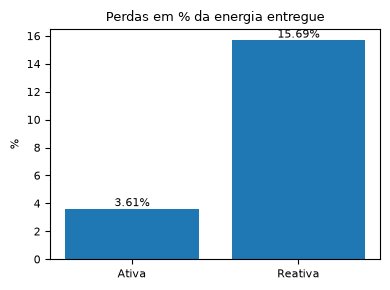

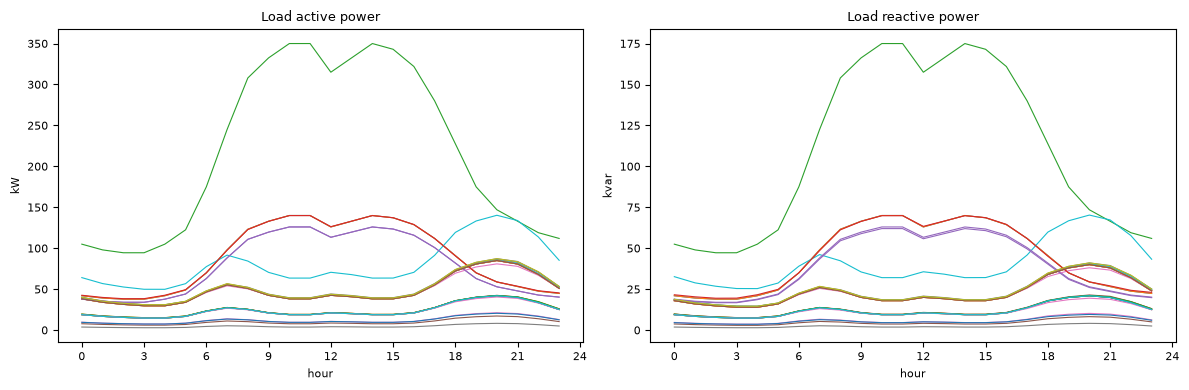

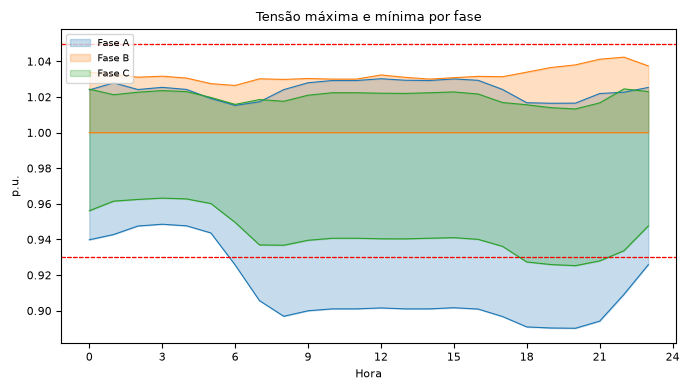

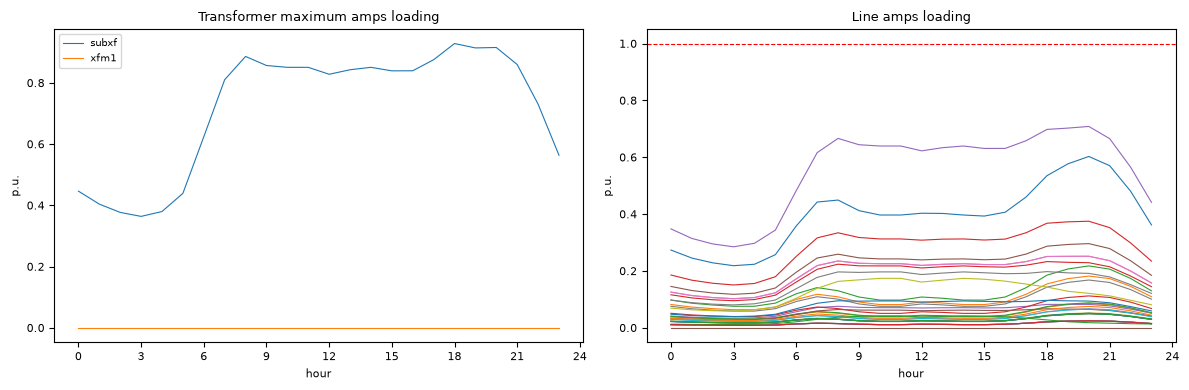

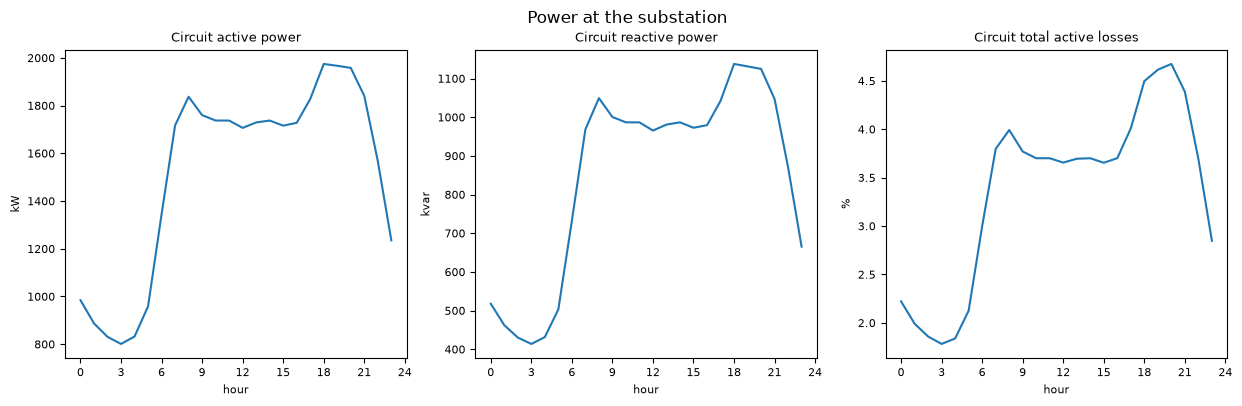

In [133]:
config["pv"] = False
config["loadmult"] = 1
simular(config)

#Simulação 2: PV false, loadmult=0.2

Total kWh delivered to the network: -7090.085 kWh
Total kVAr delivered to the network: -3409.128 kvarh
Total active losses: 48.572 kWh
Percent losses: 0.685%
Total reactive losses -43.712 kVArh
Percent reactive losses: 1.282%


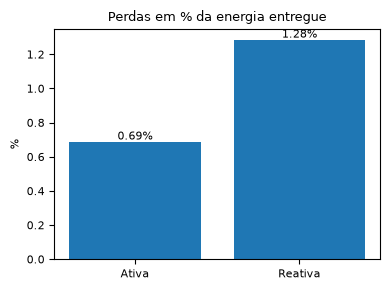

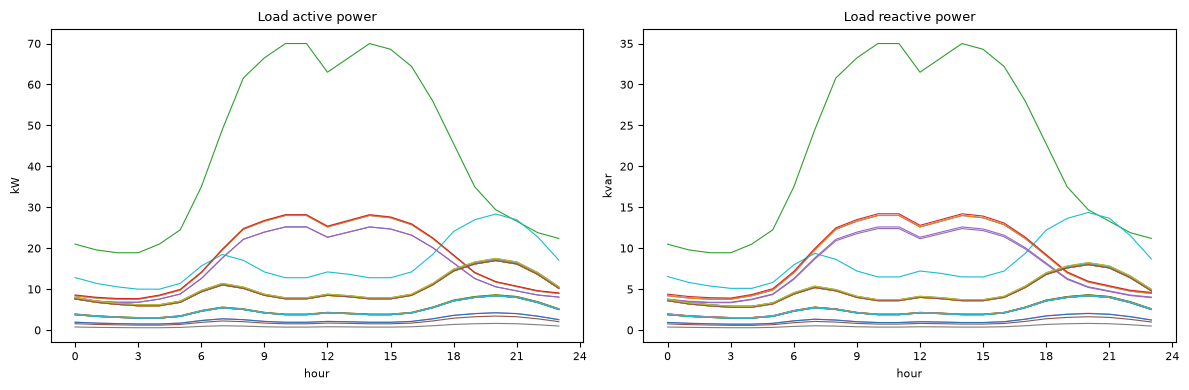

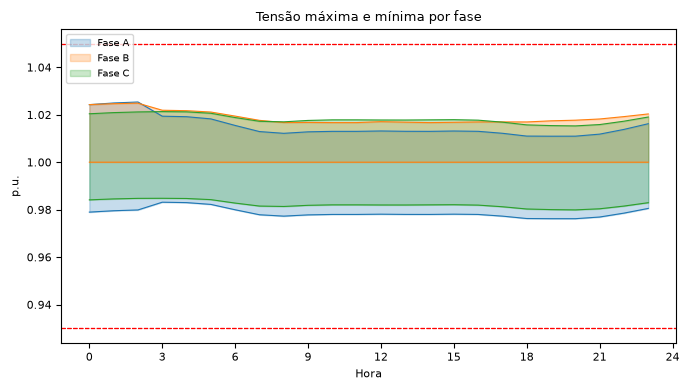

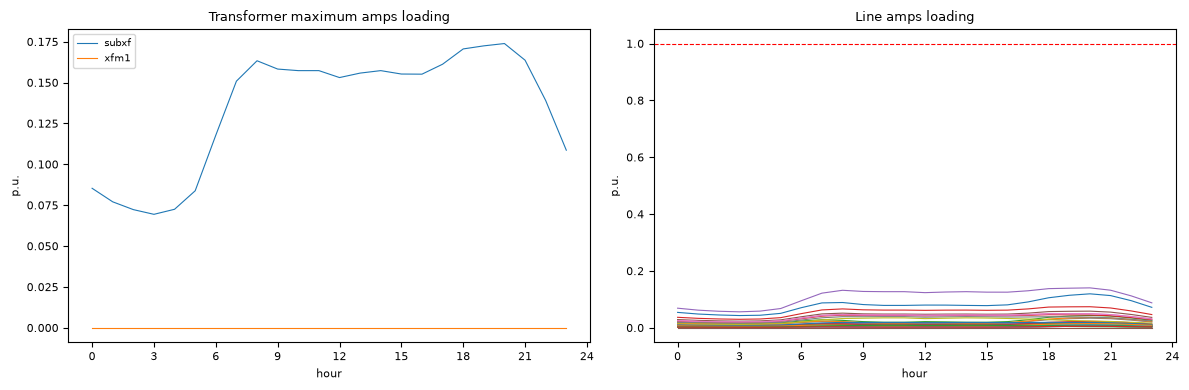

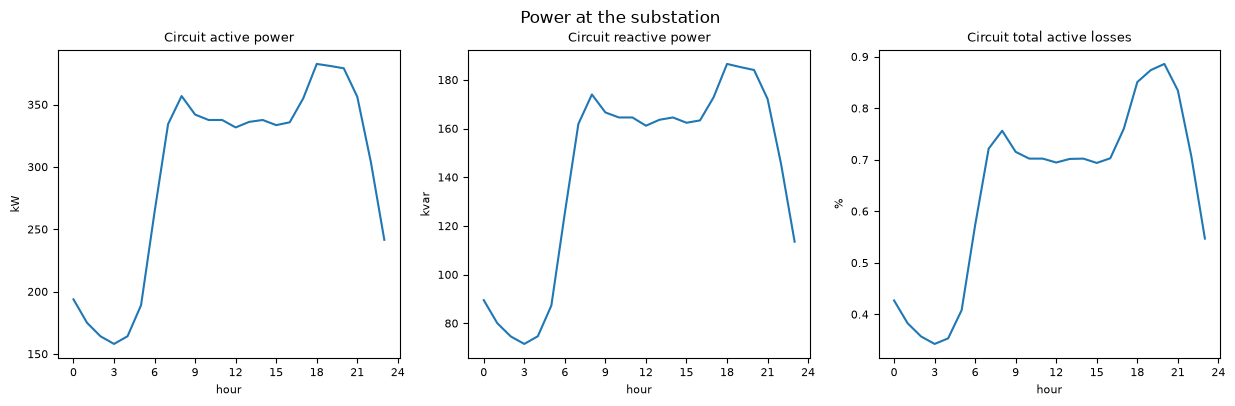

In [134]:
config["pv"] = False
config["loadmult"] = 0.2
simular(config)

#Simulação 3: PV true,  loadmult=1 pmpp=309 ,kva=345


Hora 6: violacao de tensao no noh 799.1: 0.927996217614262 p.u.
Hora 7: violacao de tensao no noh 799.1: 0.9136184784040192 p.u.
Hora 8: violacao de tensao no noh 799.1: 0.9100209509623606 p.u.
Hora 9: violacao de tensao no noh 799.1: 0.9174962250836045 p.u.
Hora 17: violacao de tensao no noh 799.1: 0.9185438427143001 p.u.
Hora 18: violacao de tensao no noh 799.1: 0.8934883117386836 p.u.
Hora 19: violacao de tensao no noh 799.1: 0.8902742073539828 p.u.
Hora 19: violacao de tensao no noh 799.3: 0.9259092565326805 p.u.
Hora 20: violacao de tensao no noh 799.1: 0.8901339160124753 p.u.
Hora 20: violacao de tensao no noh 799.3: 0.925282382240841 p.u.
Hora 21: violacao de tensao no noh 799.1: 0.894139107224925 p.u.
Hora 21: violacao de tensao no noh 799.3: 0.9279663644221435 p.u.
Hora 22: violacao de tensao no noh 799.1: 0.9091999613627209 p.u.
Hora 23: violacao de tensao no noh 799.1: 0.9258261830876862 p.u.
Total kWh delivered to the network: -19154.279 kWh
Total kVAr delivered to the netw

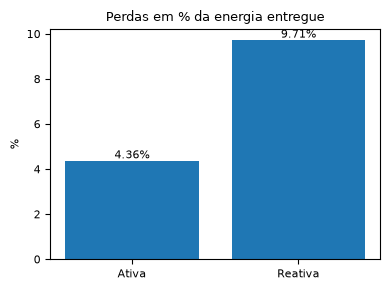

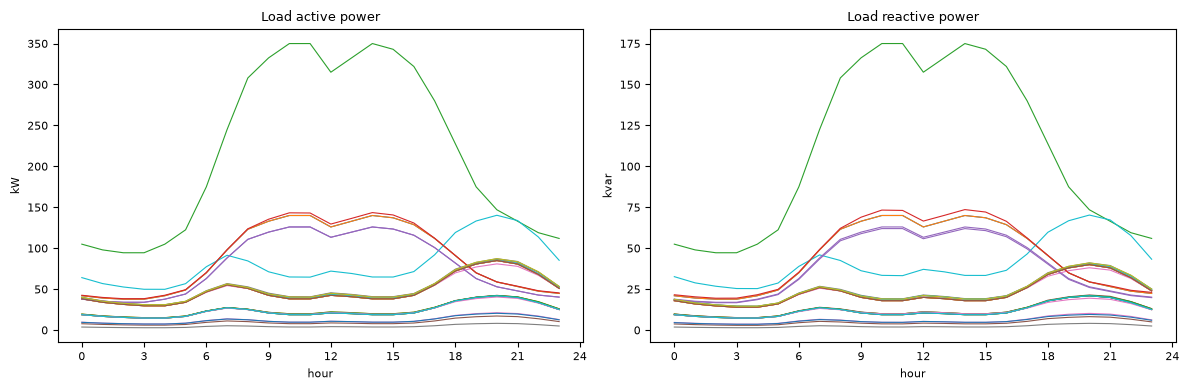

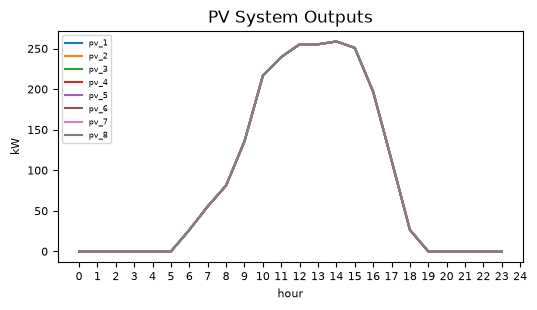

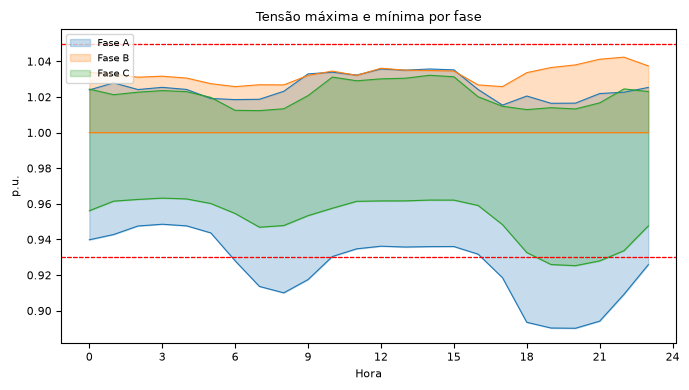

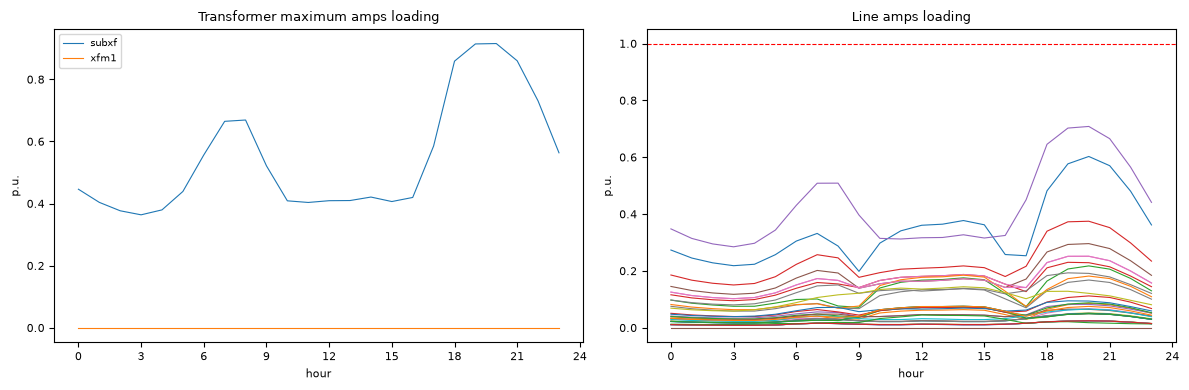

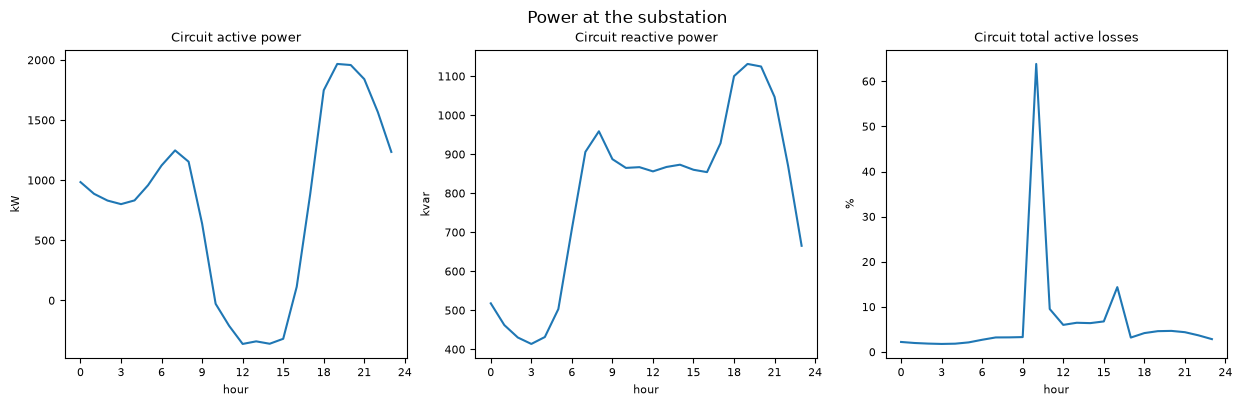

In [135]:
config["pv"] = True
config["loadmult"] = 1
simular(config)

#Simulação 4: PV true, loadmult=0.2 pmpp=309 ,kva=345

Total kWh delivered to the network: 9435.856 kWh
Total kVAr delivered to the network: -4159.696 kvarh
Total active losses: 393.353 kWh
Percent losses: 4.169%
Total reactive losses 689.577 kVArh
Percent reactive losses: 16.578%


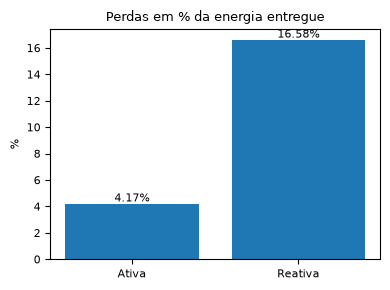

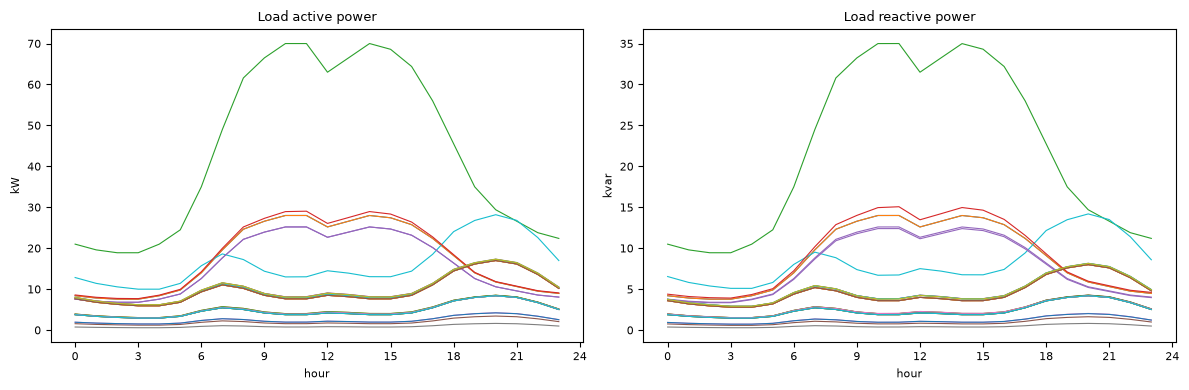

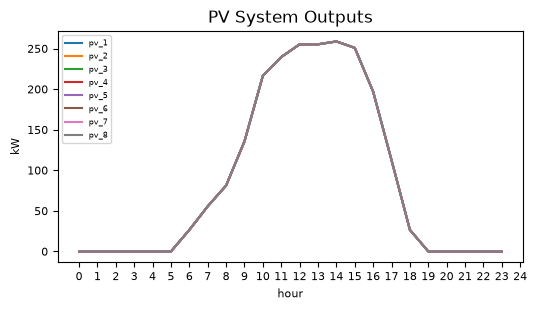

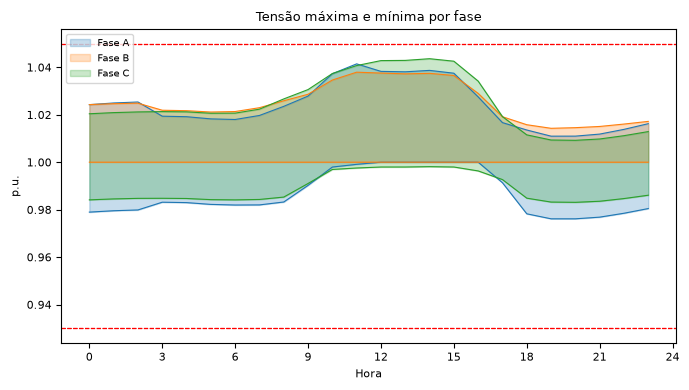

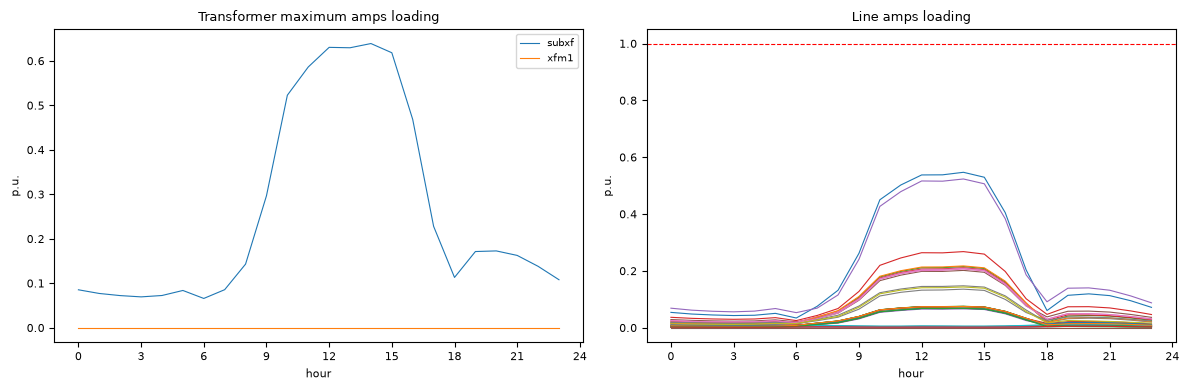

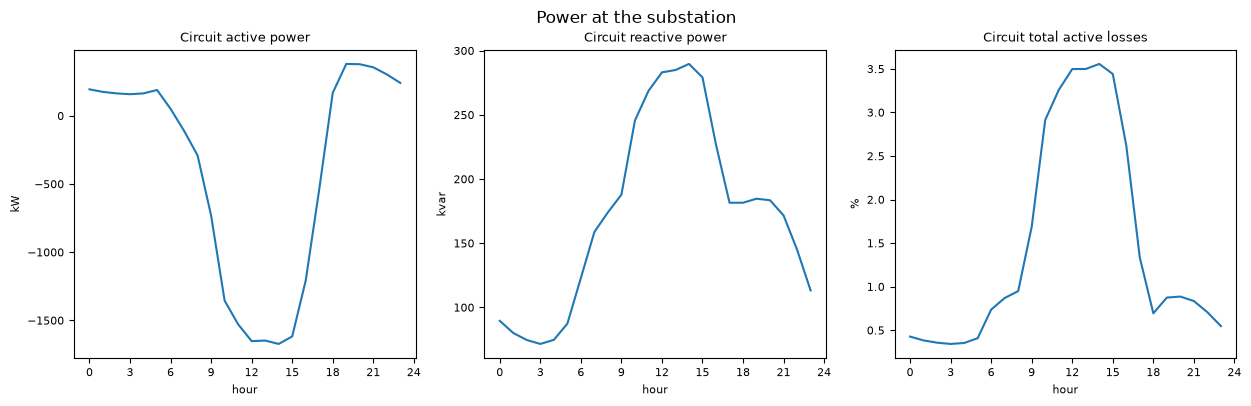

In [136]:
config["pv"] = True
config["loadmult"] = 0.2
simular(config)

#Simulação 5: PV true, loadmult=1,pmpp=400 ,kva=500


Hora 7: violacao de tensao no noh 799.1: 0.9150296876799825 p.u.
Hora 8: violacao de tensao no noh 799.1: 0.9150078324108709 p.u.
Hora 9: violacao de tensao no noh 799.1: 0.9234959946350367 p.u.
Hora 17: violacao de tensao no noh 799.1: 0.9210092274155242 p.u.
Hora 18: violacao de tensao no noh 799.1: 0.8971335443708205 p.u.
Hora 19: violacao de tensao no noh 799.1: 0.8902779104572205 p.u.
Hora 19: violacao de tensao no noh 799.3: 0.9259104328931208 p.u.
Hora 20: violacao de tensao no noh 799.1: 0.890133923680517 p.u.
Hora 20: violacao de tensao no noh 799.3: 0.9252823847696435 p.u.
Hora 21: violacao de tensao no noh 799.1: 0.8941391072265196 p.u.
Hora 21: violacao de tensao no noh 799.3: 0.92796636442236 p.u.
Hora 22: violacao de tensao no noh 799.1: 0.9091999613627209 p.u.
Hora 23: violacao de tensao no noh 799.1: 0.9258261830876862 p.u.
Total kWh delivered to the network: -14405.924 kWh
Total kVAr delivered to the network: -19255.016 kvarh
Total active losses: 910.167 kWh
Percent lo

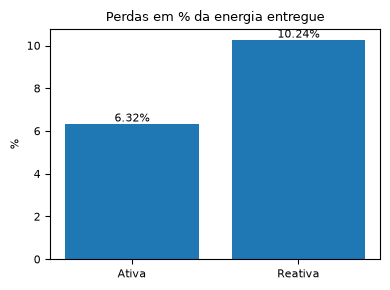

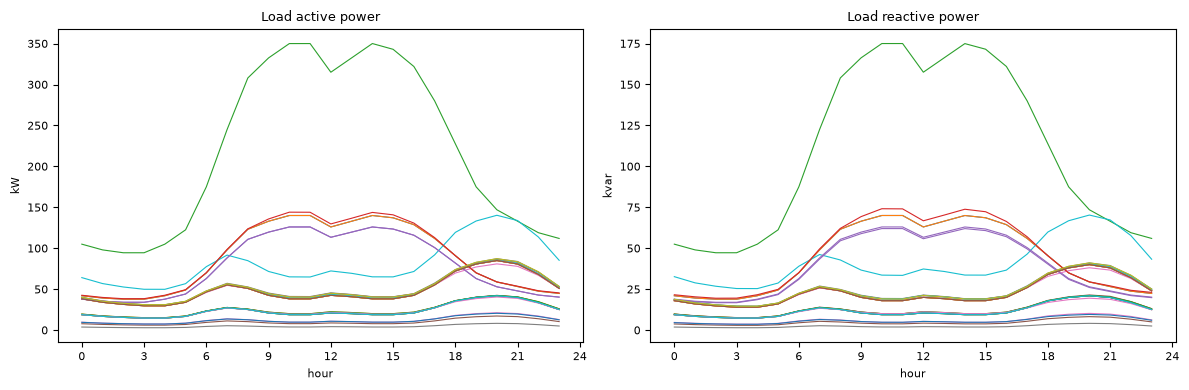

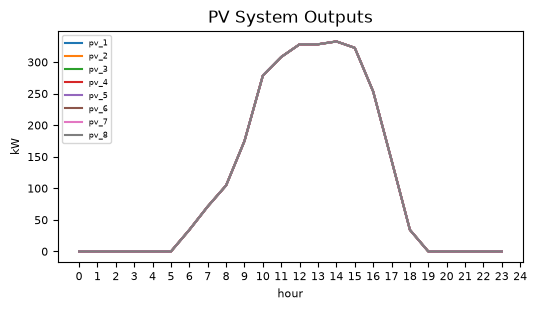

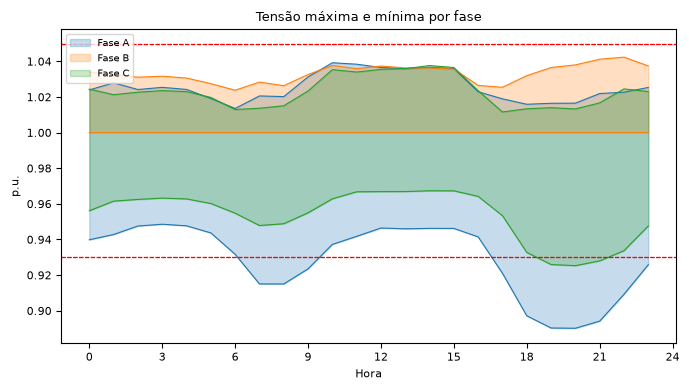

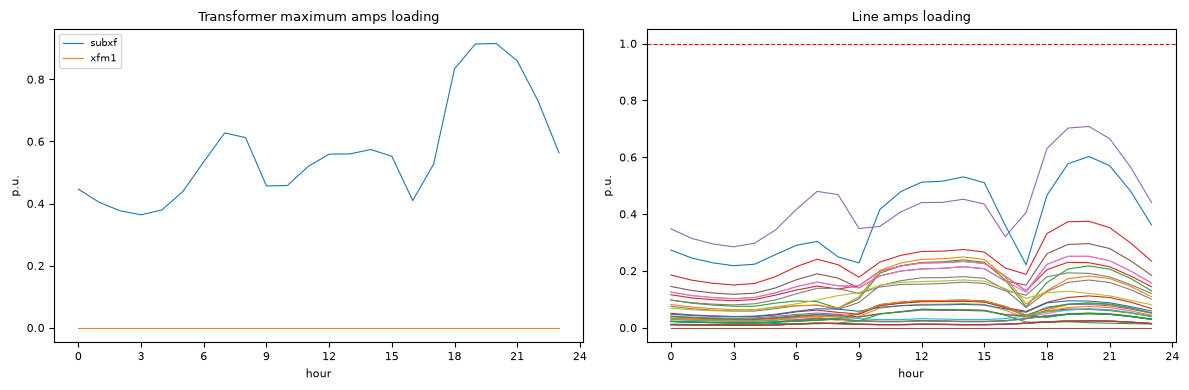

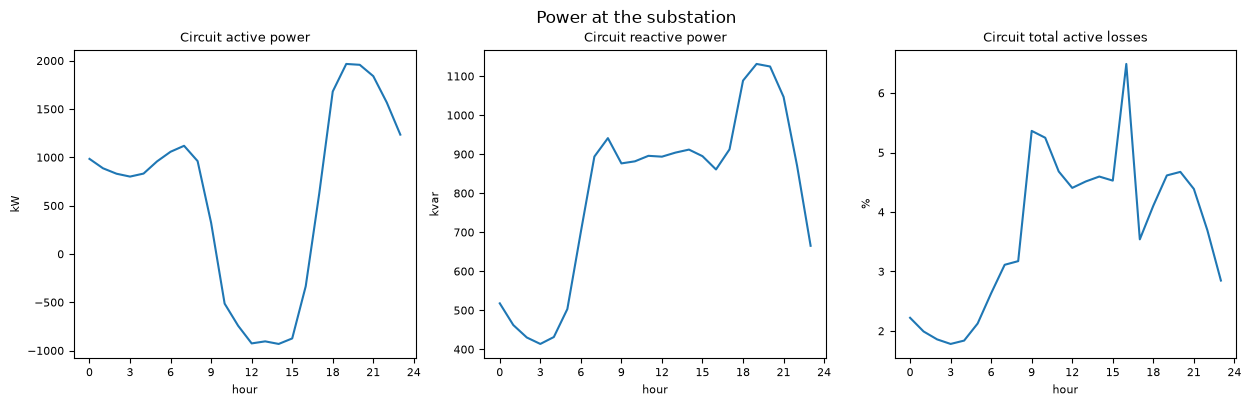

In [137]:
config["pv"] = True
config["storage"] = False
config["loadmult"] = 1
config["pv_params"]["pmpp"] = 400   #testee ver dss
config["pv_params"]["kva"] = 450    #testee ver dss
simular(config)

#Simulação 5.1 : PV true, loadmult=1,pmpp=3200 ,kva=3600


Hora 7: violacao de tensao no noh 799.1: 0.9150232048159926 p.u.
Hora 8: violacao de tensao no noh 799.1: 0.9149542169338243 p.u.
Hora 9: violacao de tensao no noh 799.1: 0.9232468403970451 p.u.
Hora 17: violacao de tensao no noh 799.1: 0.920857879247535 p.u.
Hora 18: violacao de tensao no noh 799.1: 0.897148563520582 p.u.
Hora 19: violacao de tensao no noh 799.1: 0.8902779104656703 p.u.
Hora 19: violacao de tensao no noh 799.3: 0.925910432896218 p.u.
Hora 20: violacao de tensao no noh 799.1: 0.8901339236803695 p.u.
Hora 20: violacao de tensao no noh 799.3: 0.9252823847695684 p.u.
Hora 21: violacao de tensao no noh 799.1: 0.8941391072265196 p.u.
Hora 21: violacao de tensao no noh 799.3: 0.92796636442236 p.u.
Hora 22: violacao de tensao no noh 799.1: 0.9091999613627209 p.u.
Hora 23: violacao de tensao no noh 799.1: 0.9258261830876862 p.u.
Total kWh delivered to the network: -14634.464 kWh
Total kVAr delivered to the network: -19415.678 kvarh
Total active losses: 1129.316 kWh
Percent los

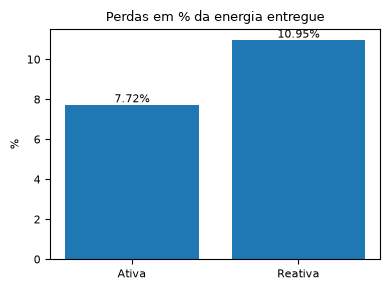

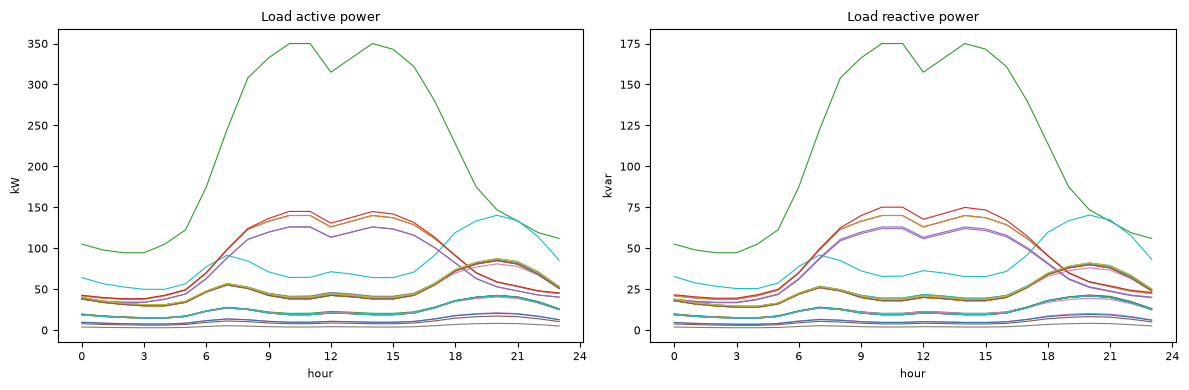

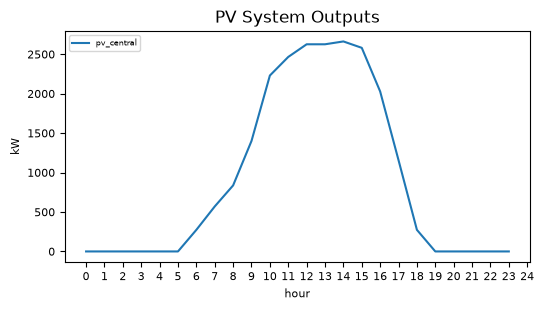

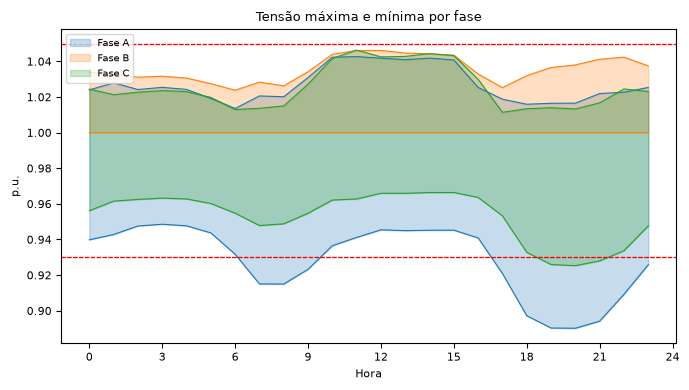

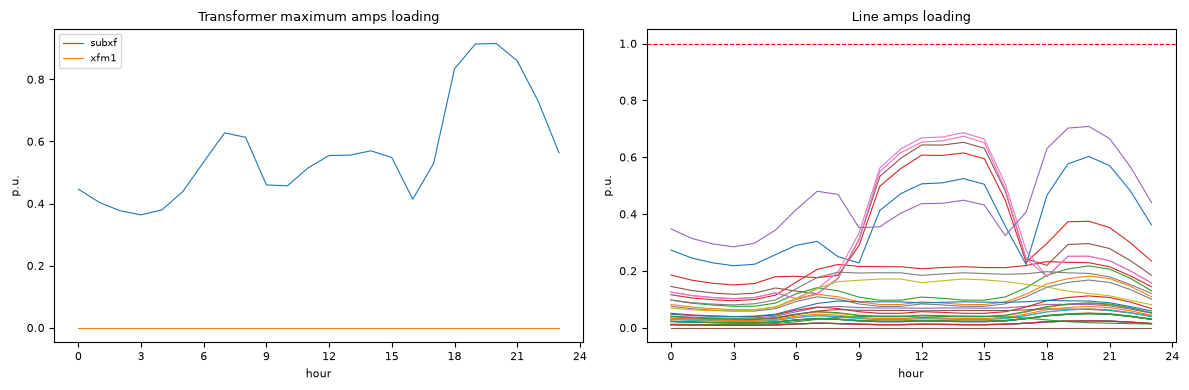

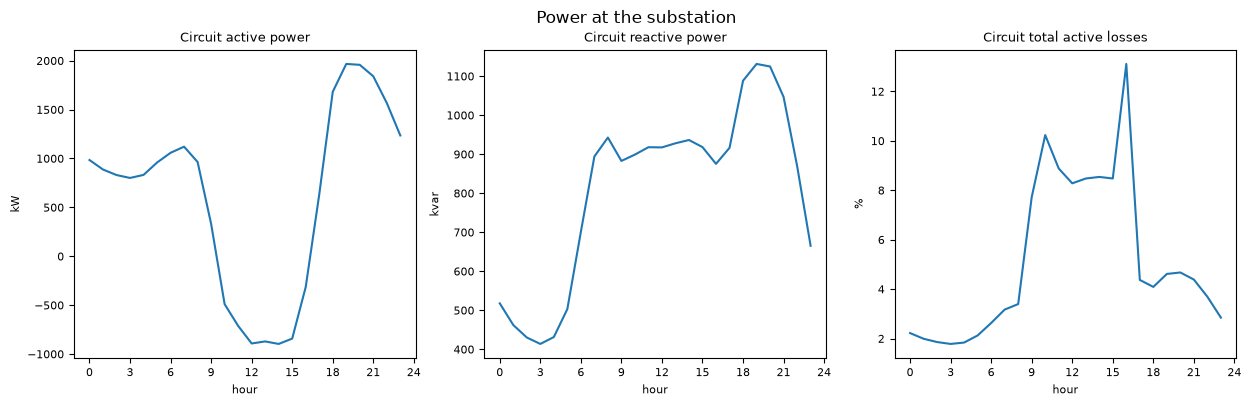

In [138]:
config["pv_params"]["nome"] = ["pv_central"]
config["pv_params"]["bus1"] = ["708.1.2.3"]
config["pv_params"]["pmpp"] = 3200   #testee ver dss
config["pv_params"]["kva"] = 3600    #testee ver dss
simular(config)

#Simulação 6: PV true, loadmult=1, pmpp=400 ,kva=500


Hora 6: violacao de tensao no noh 799.1: 0.9260779774841459 p.u.
Hora 7: violacao de tensao no noh 799.1: 0.9064296363860295 p.u.
Hora 8: violacao de tensao no noh 799.1: 0.9010709554552608 p.u.
Hora 9: violacao de tensao no noh 799.1: 0.9050325308237993 p.u.
Hora 10: violacao de tensao no noh 799.1: 0.9073740120333523 p.u.
Hora 11: violacao de tensao no noh 799.1: 0.9075495225559155 p.u.
Hora 12: violacao de tensao no noh 799.1: 0.9080514662865029 p.u.
Hora 13: violacao de tensao no noh 799.1: 0.9075420190535279 p.u.
Hora 14: violacao de tensao no noh 799.1: 0.907544346478397 p.u.
Hora 15: violacao de tensao no noh 799.1: 0.9081697381467405 p.u.
Hora 16: violacao de tensao no noh 799.1: 0.906948749633246 p.u.
Hora 17: violacao de tensao no noh 799.1: 0.9014651191312385 p.u.
Hora 18: violacao de tensao no noh 799.1: 0.8913529918590618 p.u.
Hora 18: violacao de tensao no noh 799.3: 0.9276692053992374 p.u.
Hora 19: violacao de tensao no noh 799.1: 0.8902857487371145 p.u.
Hora 19: violaca

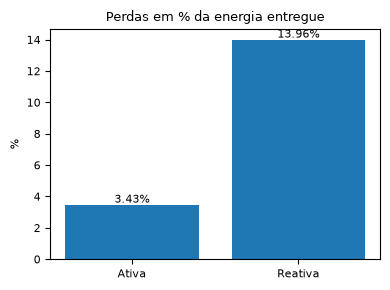

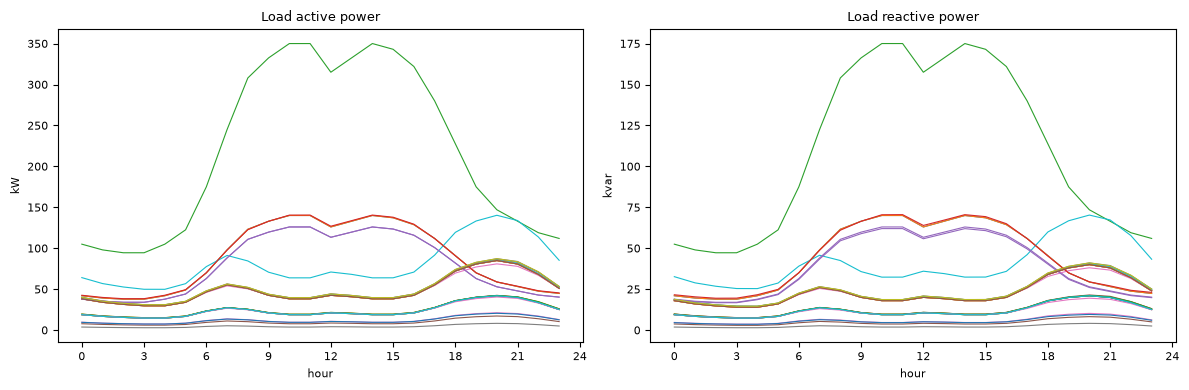

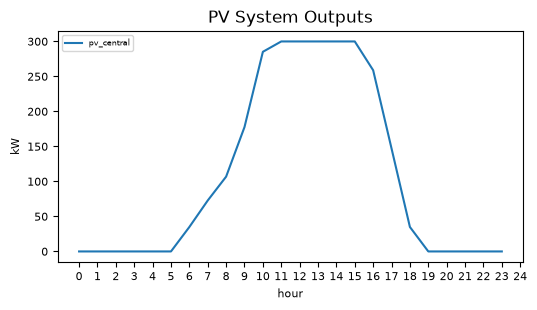

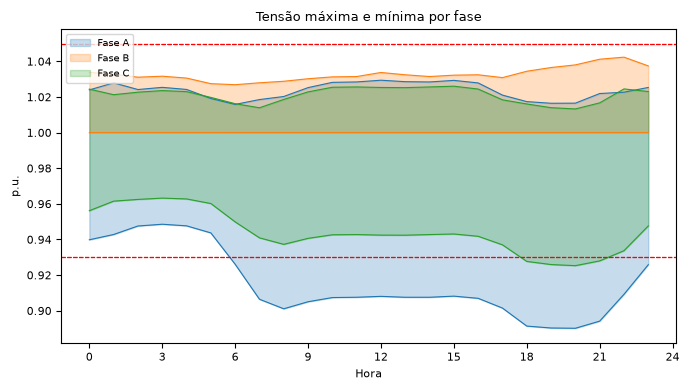

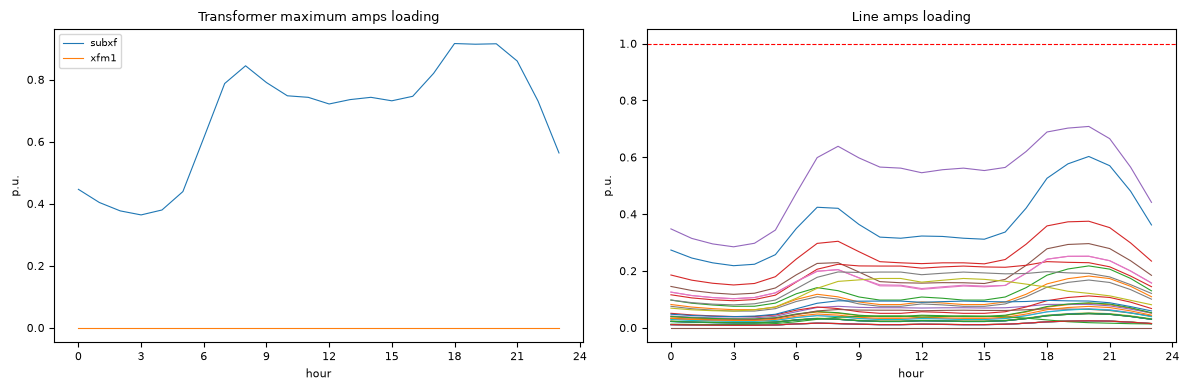

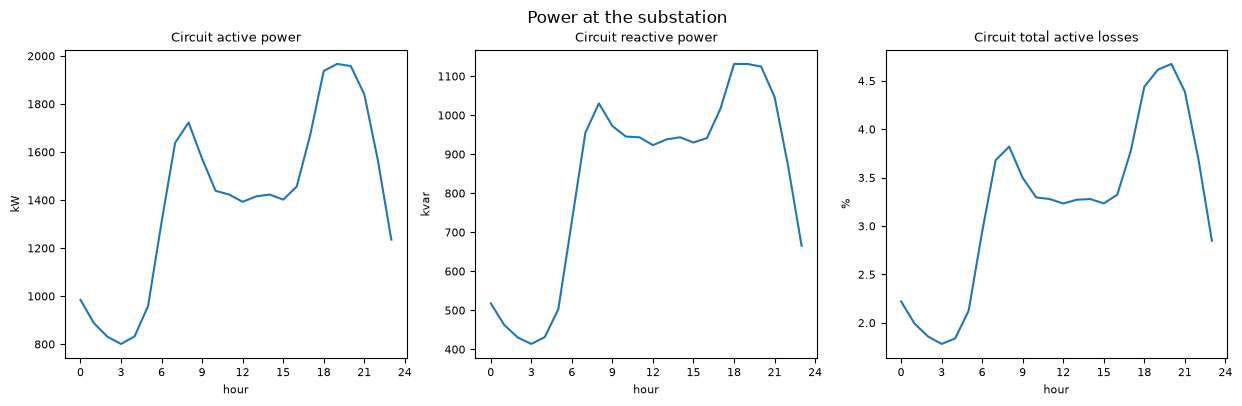

In [139]:
config["pv"] = True
config["storage"] = False
config["loadmult"] = 1
config["pv_params"]["pmpp"] = 400   #testee ver dss
config["pv_params"]["kva"] = 300    #testee ver dss
simular(config)

#Simulação 7: PV true, loadmult=1, pmpp=400 ,kva=500


Hora 6: violacao de tensao no noh 799.1: 0.9260779774841459 p.u.
Hora 7: violacao de tensao no noh 799.1: 0.9064296363860295 p.u.
Hora 8: violacao de tensao no noh 799.1: 0.9010709554552608 p.u.
Hora 9: violacao de tensao no noh 799.1: 0.9050325308237993 p.u.
Hora 10: violacao de tensao no noh 799.1: 0.9073740120333523 p.u.
Hora 11: violacao de tensao no noh 799.1: 0.9075495225559155 p.u.
Hora 12: violacao de tensao no noh 799.1: 0.9080514662865029 p.u.
Hora 13: violacao de tensao no noh 799.1: 0.9075420190535279 p.u.
Hora 14: violacao de tensao no noh 799.1: 0.907544346478397 p.u.
Hora 15: violacao de tensao no noh 799.1: 0.9081697381467405 p.u.
Hora 16: violacao de tensao no noh 799.1: 0.906948749633246 p.u.
Hora 17: violacao de tensao no noh 799.1: 0.9014651191312385 p.u.
Hora 18: violacao de tensao no noh 799.1: 0.8913529918590618 p.u.
Hora 18: violacao de tensao no noh 799.3: 0.9276692053992374 p.u.
Hora 19: violacao de tensao no noh 799.1: 0.8902857487371145 p.u.
Hora 19: violaca

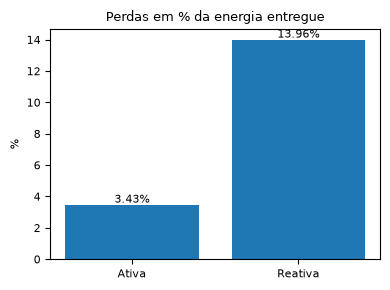

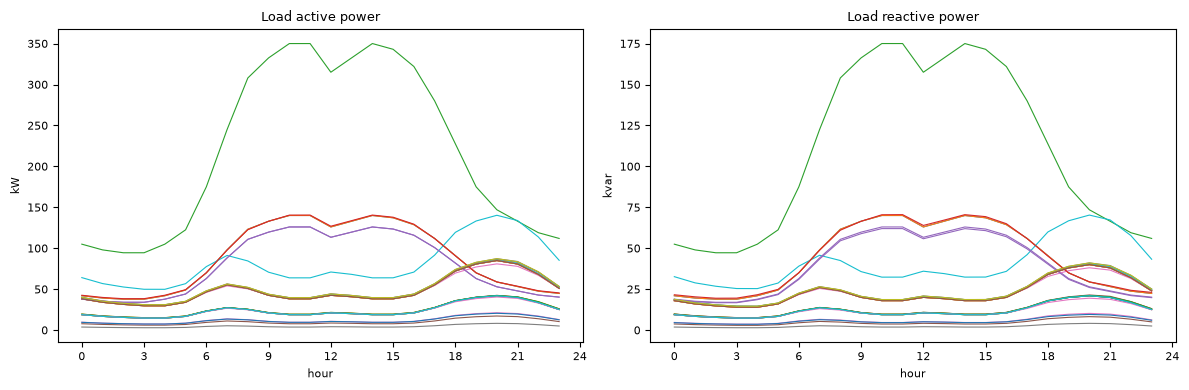

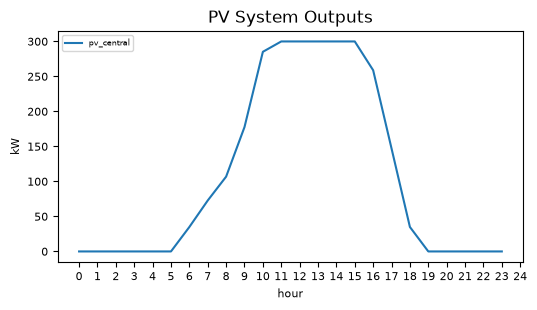

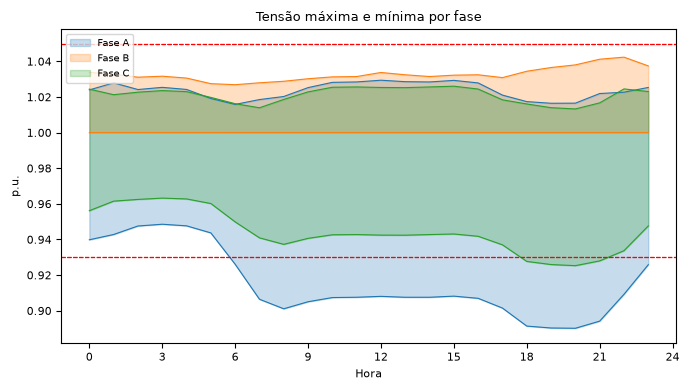

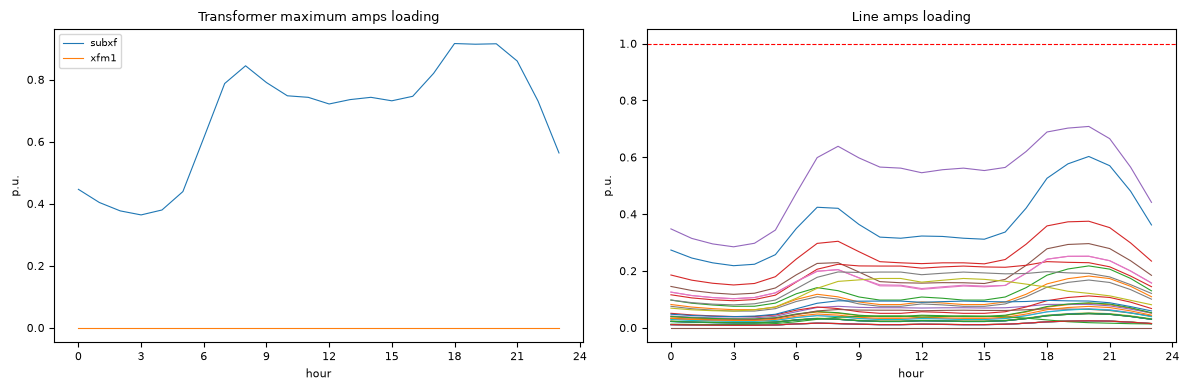

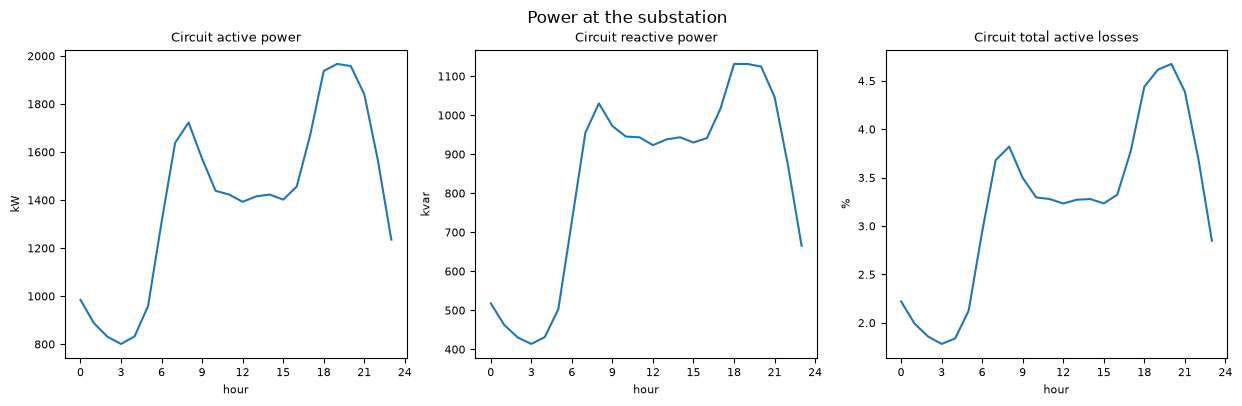

In [140]:
config["pv"] = True
config["storage"] = False
config["loadmult"] = 1
config["pv_params"]["pmpp"] = 400   #testee ver dss
config["pv_params"]["kva"] = 300    #testee ver dss
simular(config)

#Simulação 8: PV true, loadmult=1, pmpp=400 ,kva=500


Hora 6: violacao de tensao no noh 799.1: 0.9260779774841459 p.u.
Hora 7: violacao de tensao no noh 799.1: 0.9064296363860295 p.u.
Hora 8: violacao de tensao no noh 799.1: 0.9010709554552608 p.u.
Hora 9: violacao de tensao no noh 799.1: 0.9050325308237993 p.u.
Hora 10: violacao de tensao no noh 799.1: 0.9073740120333523 p.u.
Hora 11: violacao de tensao no noh 799.1: 0.9075495225559155 p.u.
Hora 12: violacao de tensao no noh 799.1: 0.9080514662865029 p.u.
Hora 13: violacao de tensao no noh 799.1: 0.9075420190535279 p.u.
Hora 14: violacao de tensao no noh 799.1: 0.907544346478397 p.u.
Hora 15: violacao de tensao no noh 799.1: 0.9081697381467405 p.u.
Hora 16: violacao de tensao no noh 799.1: 0.906948749633246 p.u.
Hora 17: violacao de tensao no noh 799.1: 0.9014651191312385 p.u.
Hora 18: violacao de tensao no noh 799.1: 0.8913529918590618 p.u.
Hora 18: violacao de tensao no noh 799.3: 0.9276692053992374 p.u.
Hora 19: violacao de tensao no noh 799.1: 0.8902857487371145 p.u.
Hora 19: violaca

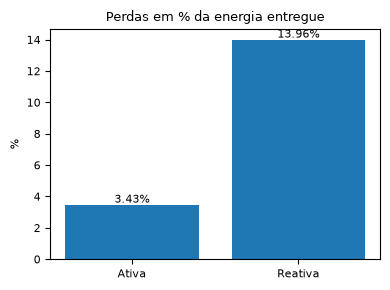

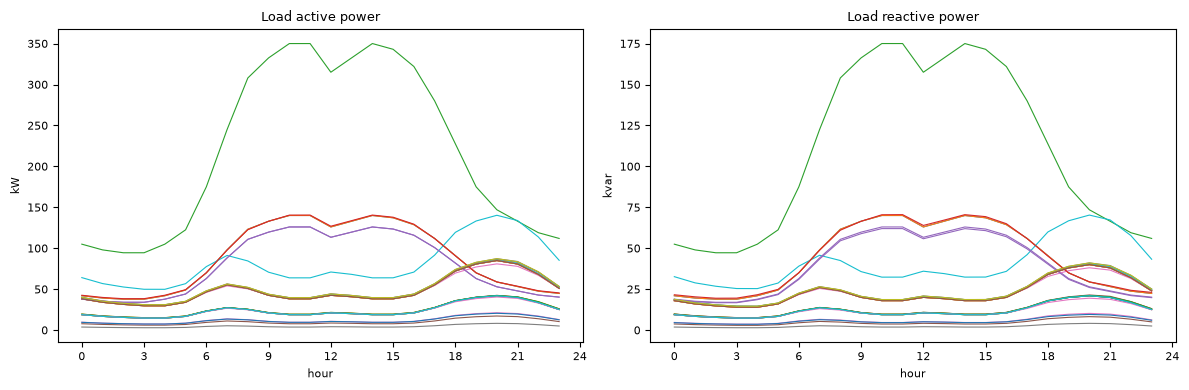

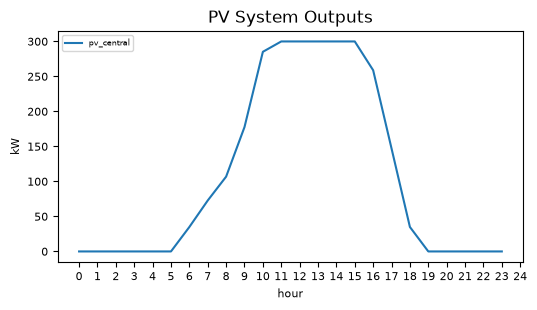

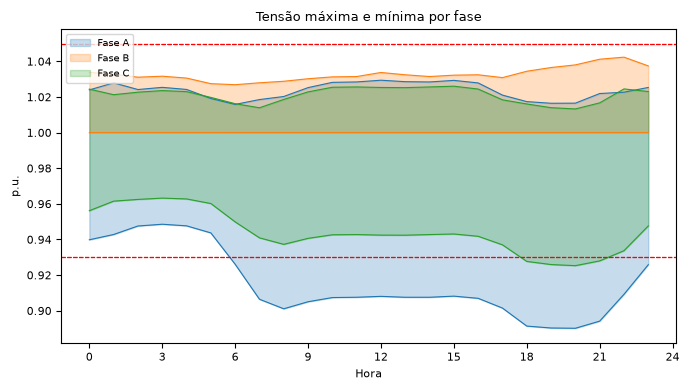

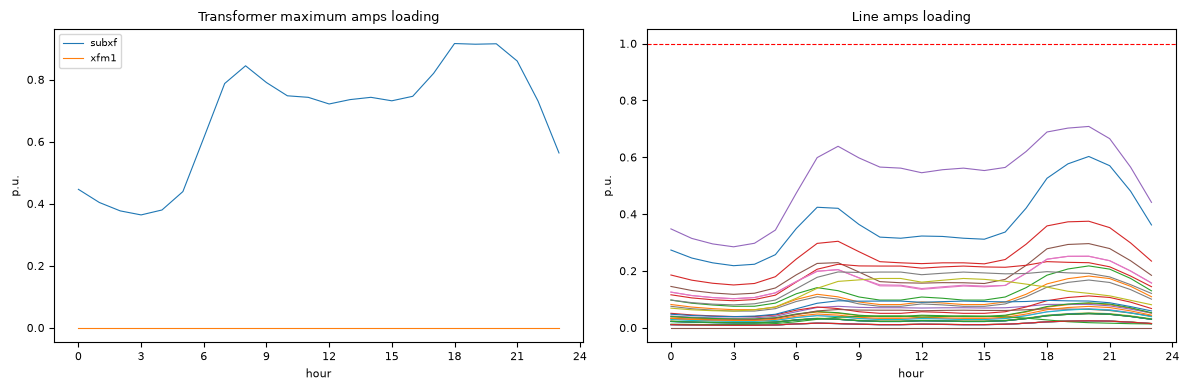

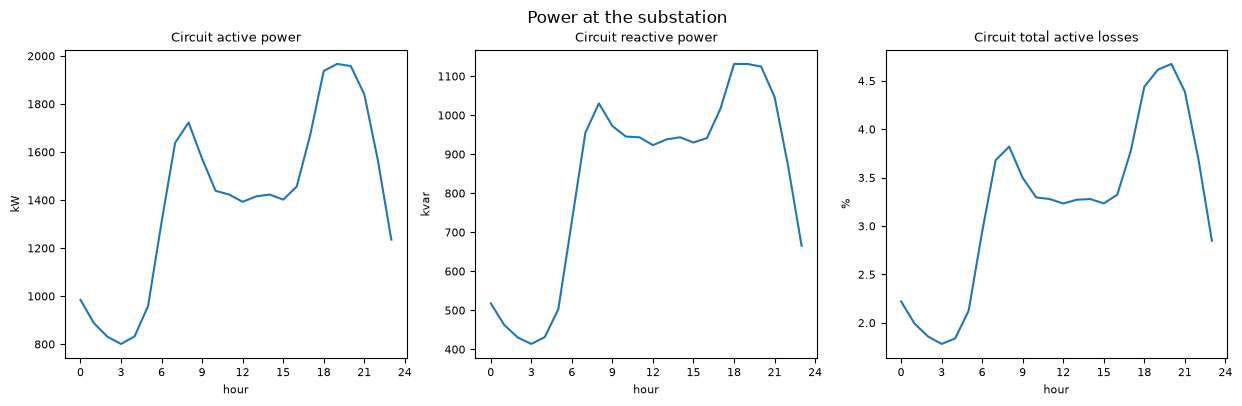

In [141]:
config["pv"] = True
config["storage"] = False
config["loadmult"] = 1
config["pv_params"]["pmpp"] = 400   #testee ver dss
config["pv_params"]["kva"] = 300    #testee ver dss
simular(config)

#Simulação 9: PV true, loadmult=1, pmpp=400 ,kva=500

Hora 6: violacao de tensao no noh 799.1: 0.9260779774841459 p.u.
Hora 7: violacao de tensao no noh 799.1: 0.9064296363860295 p.u.
Hora 8: violacao de tensao no noh 799.1: 0.9010709554552608 p.u.
Hora 9: violacao de tensao no noh 799.1: 0.9050325308237993 p.u.
Hora 10: violacao de tensao no noh 799.1: 0.9073740120333523 p.u.
Hora 11: violacao de tensao no noh 799.1: 0.9075495225559155 p.u.
Hora 12: violacao de tensao no noh 799.1: 0.9080514662865029 p.u.
Hora 13: violacao de tensao no noh 799.1: 0.9075420190535279 p.u.
Hora 14: violacao de tensao no noh 799.1: 0.907544346478397 p.u.
Hora 15: violacao de tensao no noh 799.1: 0.9081697381467405 p.u.
Hora 16: violacao de tensao no noh 799.1: 0.906948749633246 p.u.
Hora 17: violacao de tensao no noh 799.1: 0.9014651191312385 p.u.
Hora 18: violacao de tensao no noh 799.1: 0.8913529918590618 p.u.
Hora 18: violacao de tensao no noh 799.3: 0.9276692053992374 p.u.
Hora 19: violacao de tensao no noh 799.1: 0.8902857487371145 p.u.
Hora 19: violaca

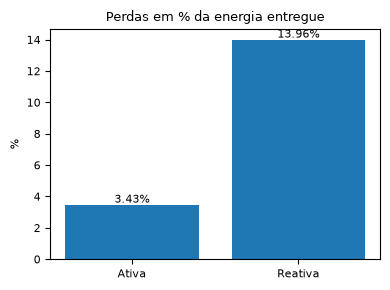

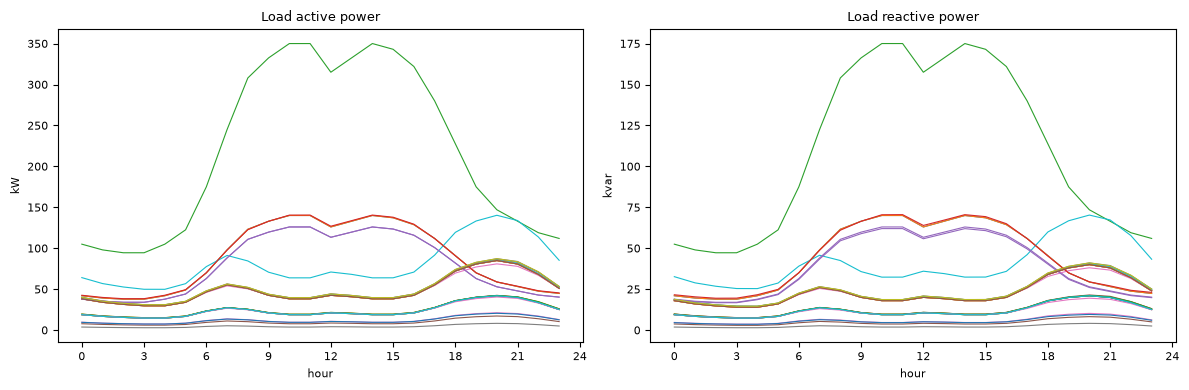

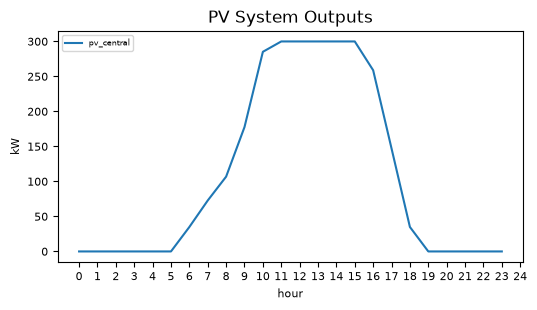

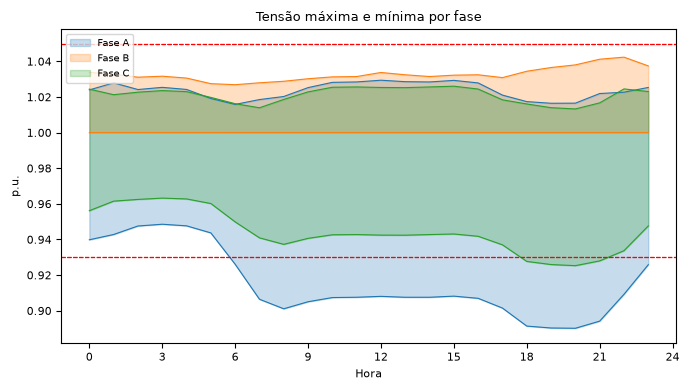

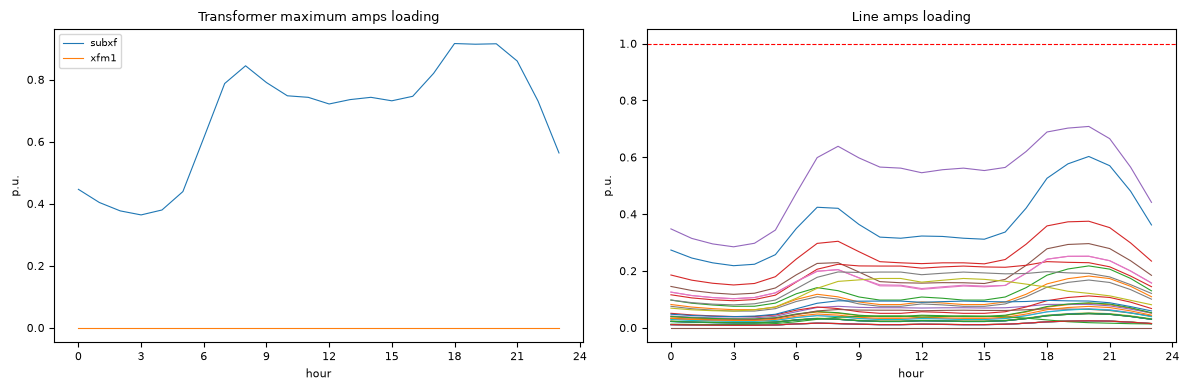

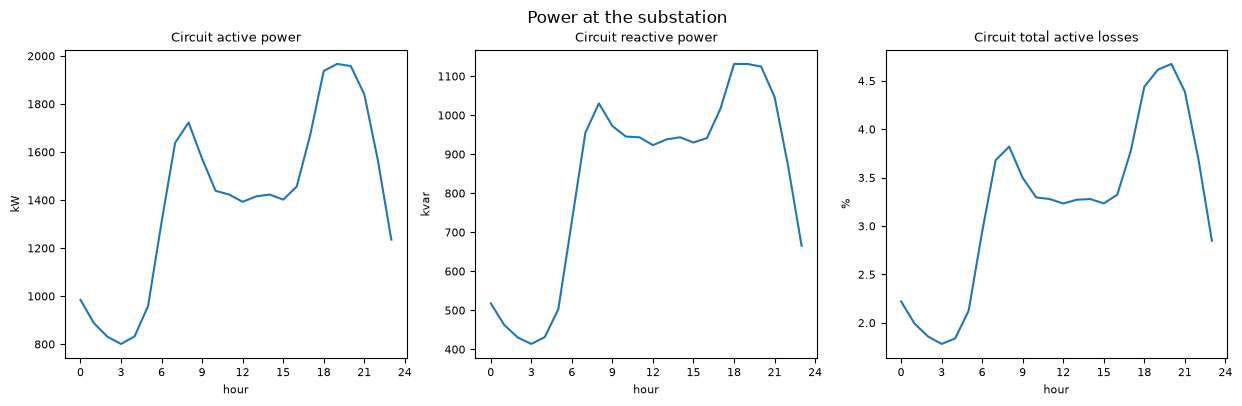

In [142]:
config["pv"] = True
config["storage"] = False
config["loadmult"] = 1
config["pv_params"]["pmpp"] = 400   #testee ver dss
config["pv_params"]["kva"] = 300    #testee ver dss
simular(config)

#Simulação 10: PV true, loadmult=1, pmpp=400 ,kva=500

Hora 6: violacao de tensao no noh 799.1: 0.9260209782796492 p.u.
Hora 7: violacao de tensao no noh 799.1: 0.9063695492655535 p.u.
Hora 8: violacao de tensao no noh 799.1: 0.9010099379667104 p.u.
Hora 9: violacao de tensao no noh 799.1: 0.9049734597029583 p.u.
Hora 10: violacao de tensao no noh 799.1: 0.9059426069167907 p.u.
Hora 11: violacao de tensao no noh 799.1: 0.9056359241138946 p.u.
Hora 12: violacao de tensao no noh 799.1: 0.9059029516055697 p.u.
Hora 13: violacao de tensao no noh 799.1: 0.9053828500954992 p.u.
Hora 14: violacao de tensao no noh 799.1: 0.9053876733255646 p.u.
Hora 15: violacao de tensao no noh 799.1: 0.9062599350106053 p.u.
Hora 16: violacao de tensao no noh 799.1: 0.9062313175711331 p.u.
Hora 17: violacao de tensao no noh 799.1: 0.9024502671033826 p.u.
Hora 18: violacao de tensao no noh 799.1: 0.8932701706723886 p.u.
Hora 19: violacao de tensao no noh 799.1: 0.8932478787393247 p.u.
Hora 20: violacao de tensao no noh 799.1: 0.8931068026978988 p.u.
Hora 21: viola

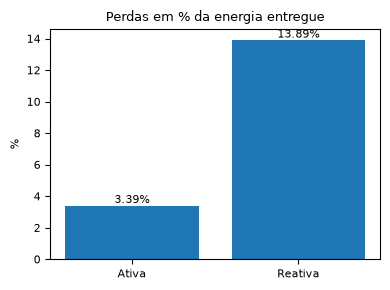

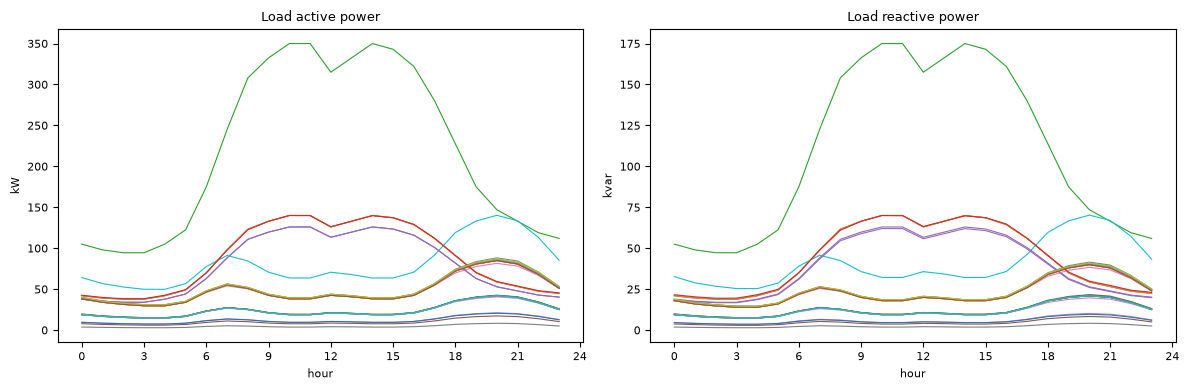

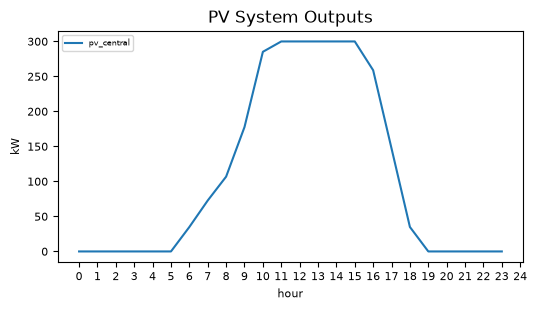

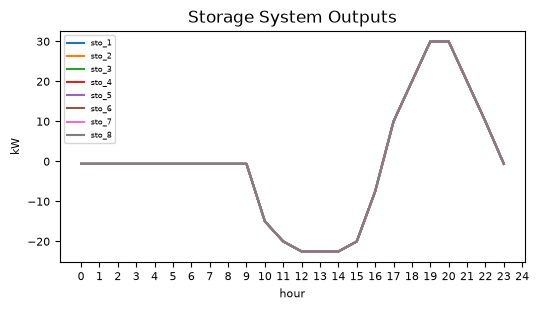

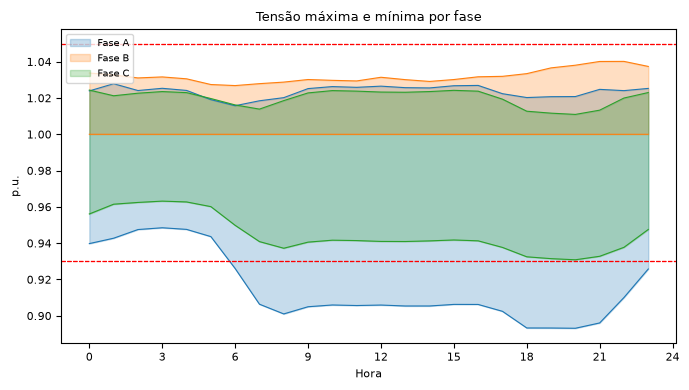

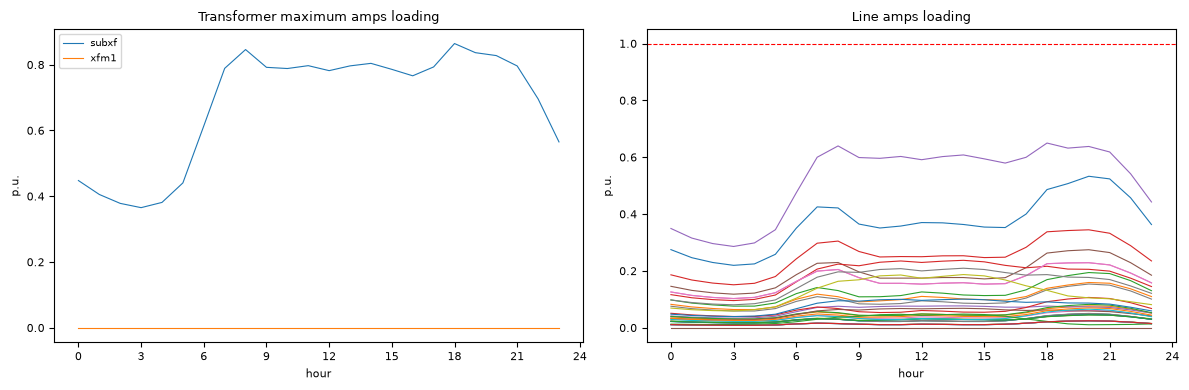

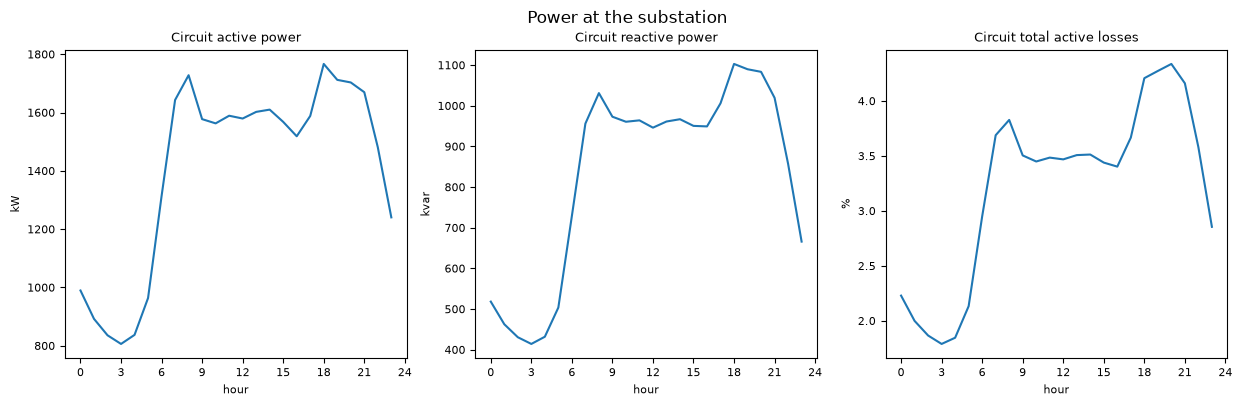

In [143]:
config["pv"] = True
config["storage"] = True
config["loadmult"] = 1
config["pv_params"]["pmpp"] = 400   #testee ver dss
config["pv_params"]["kva"] = 300    #testee ver dss
simular(config)